## **Постановка задачи**
* Сделать рекомендательную систему на главной странице интернет-магазина (3 слота товаров на главной странице)
## **Бизнес-цель**
* Повысить прибыль от допродаж в интернет-магазине на 20 %. Перспектива - A/B тест
## **Метрика**
* Precision@3 на покупках за следующие 14 дней (метрика Precision@3 не измеряет прибыль. Для данной цели потребуется A/B тест) 
## **Схема валидации**
* Разбиение **по времени**: test — последние 14 дней данных, validation — 14 дней перед ним, train — всё раньше (границы: 2015-08-21 02:59:47 и 2015-09-04 02:59:47, конец данных — 2015-09-18 02:59:47)
* Признаки считаются только по событиям **до** границы; цель — покупки в **следующие 14 дней**
* Модель выбирается по Precision@3 на validation; test считается **один раз**, в самом конце
## **Порядок запуска**
1. `pip install -r requirements.txt`
2. Положить `events.csv`, `category_tree.csv`, `item_properties_part1.csv`, `item_properties_part2.csv` в папку `data/` (или рядом с ноутбуком)
3. `Kernel → Restart & Run All`
4. Результаты — в папке `results/`, артефакты сервиса — в `artifacts/`

## **Описание данных**

**events** — датасет с событиями

* timestamp — время события
* visitorid — идентификатор пользователя
* event — тип события
* itemid — идентификатор объекта
* transactionid — идентификатор транзакции, если она проходила

**category_tree** — файл с деревом категорий (можно восстановить дерево).

* categoryid — идентификатор категорий
* parentid — идентификатор родительской категории

**item_properties** — файл с свойствами товаров

* timestamp — момент записи значения свойства
* itemid — идентификатор объекта
* property — свойство; осмысленны только categoryid и available, остальные захешированы
* value — значение свойства

**Комментарий**
* **Установите зависимости: `pip install -r requirements.txt`**

In [1]:
import time
RUN_START = time.time()

In [2]:
%%writefile requirements.txt
pandas>=2.0
numpy>=1.26
scipy>=1.11
scikit-learn>=1.4
matplotlib>=3.8
implicit>=0.7
xgboost>=2.0
jupyter

Overwriting requirements.txt


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import implicit

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

# Переменные
K = 3                                                   # сколько товаров рекомендуем
SEED = 42                                               # фиксируем случайность
TEST_DAYS = 14                                          # длина test
VAL_DAYS = 14                                           # длина validation
HORIZON_DAYS = 14                                       # горизонт прогноза покупок
EVENT_WEIGHTS = {'view': 1, 'addtocart': 5, 'transaction': 15}   # веса действий (выбраны на validation)
SMOOTHING_ALPHA = 5                                     # сила сглаживания конверсии

In [4]:
# Пути проекта: папка с данными и папка для результатов.
BASE_DIR = Path.cwd()                                    # папка, из которой запущен ноутбук
DATA_DIR = BASE_DIR / 'data' if (BASE_DIR / 'data' / 'events.csv').exists() else BASE_DIR
RESULTS_DIR = BASE_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
# Загрузка данных
events_df = pd.read_csv(DATA_DIR / "events.csv")
category_tree_df = pd.read_csv(DATA_DIR / "category_tree.csv")

# Подготовка к чтению большого файла свойств товаров
PROPS_TO_KEEP = ('categoryid', 'available') # из 1104 свойств нам нужны только эти два
properties_stats = {'rows': 0, 'property_types': set()} # счётчики: сколько всего строк и какие бывают свойства
parts = []

# Читаем два файла свойств по частям
for part_name in ("item_properties_part1.csv", "item_properties_part2.csv"):
    for chunk in pd.read_csv(DATA_DIR / part_name, chunksize=2_000_000, dtype={'property': str, 'value': str}):
        properties_stats['rows'] += len(chunk)
        properties_stats['property_types'].update(chunk['property'].unique())
        parts.append(chunk[chunk['property'].isin(PROPS_TO_KEEP)])
# Склейка
properties_df = pd.concat(parts, ignore_index=True)          # ТОЛЬКО categoryid и available
properties_stats['property_types'] = len(properties_stats['property_types'])
del parts, chunk                                  # освобождаем память

# timestamp переводим в дату
events_df["date"] = pd.to_datetime(events_df["timestamp"], unit='ms')
properties_df["date"] = pd.to_datetime(properties_df["timestamp"], unit='ms')

print(events_df['date'].min())
print(events_df['date'].max())
display(events_df[['timestamp', 'date']].head())
print()
print("Events shape:", events_df.shape)
print("Category tree shape:", category_tree_df.shape)
print("Properties: всего строк", properties_stats['rows'], "| разных свойств", properties_stats['property_types'],
      "| оставлено (categoryid, available):", properties_df.shape)

2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000


,timestamp,date
0,1433221332117,2015-06-02 05:02:12.117
1,1433224214164,2015-06-02 05:50:14.164
2,1433221999827,2015-06-02 05:13:19.827
3,1433221955914,2015-06-02 05:12:35.914
4,1433221337106,2015-06-02 05:02:17.106



Events shape: (2756101, 6)
Category tree shape: (1669, 2)
Properties: всего строк 20275902 | разных свойств 1104 | оставлено (categoryid, available): (2291853, 5)


In [6]:
display(events_df.head())
display(events_df.info())
print()
display(category_tree_df.head()) 
display(category_tree_df.info())
print()
display(properties_df.head())
display(properties_df.info())

,timestamp,visitorid,event,itemid,transactionid,date
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 6 columns):
 #   Column         Dtype         
---  ------         -----         
 0   timestamp      int64         
 1   visitorid      int64         
 2   event          object        
 3   itemid         int64         
 4   transactionid  float64       
 5   date           datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 126.2+ MB


None

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1669 entries, 0 to 1668
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   categoryid  1669 non-null   int64  
 1   parentid    1644 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 26.2 KB


None

,timestamp,itemid,property,value,date
0,1435460400000,460429,categoryid,1338,2015-06-28 03:00:00
1,1436065200000,285026,available,0,2015-07-05 03:00:00
2,1437274800000,186518,available,0,2015-07-19 03:00:00
3,1433646000000,423682,available,0,2015-06-07 03:00:00
4,1434250800000,316253,available,1,2015-06-14 03:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2291853 entries, 0 to 2291852
Data columns (total 5 columns):
 #   Column     Dtype         
---  ------     -----         
 0   timestamp  int64         
 1   itemid     int64         
 2   property   object        
 3   value      object        
 4   date       datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 87.4+ MB


None

In [7]:
display(events_df['event'].value_counts())
display(events_df['event'].value_counts(normalize=True) * 100)
display(events_df['visitorid'].value_counts())
display(events_df['visitorid'].value_counts().mean())
display(events_df['visitorid'].value_counts().median())

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

event
view           96.669607
addtocart       2.515583
transaction     0.814810
Name: proportion, dtype: float64

visitorid
1150086    7757
530559     4328
152963     3024
895999     2474
163561     2410
           ... 
877104        1
1015187       1
1214670       1
648716        1
301110        1
Name: count, Length: 1407580, dtype: int64

np.float64(1.9580421716705267)

np.float64(1.0)

**Комментарий**
* Данные сильно несбалансированы по типам взаимодействий
* Примерно 97 из 100 событий - просто просмотр товара, около 2.5 - добавление в корзину и меньше 1 - покупка
* Покупка обычно представляет значительно более сильный сигнал пользовательского интереса, чем просмотр. Позже это можно учесть при построении implicit-рекомендаций, например назначением разных весов взаимодействия
* В датасете 1407580 уникальных пользователей. Активность пользователей распределена очень неравномерно
* Типичный пользователь имеет очень мало взаимодействий, а небольшая группа активных пользователей увеличивает среднее. И для рекомендательной системы это критично: если у пользователя только одно действие, персонализировать рекомендации для него намного сложнее. Это связано с проблемой недостаточной истории пользователя и частично с cold start

In [8]:
events_df[['timestamp', 'date']].head()

,timestamp,date
0,1433221332117,2015-06-02 05:02:12.117
1,1433224214164,2015-06-02 05:50:14.164
2,1433221999827,2015-06-02 05:13:19.827
3,1433221955914,2015-06-02 05:12:35.914
4,1433221337106,2015-06-02 05:02:17.106


In [9]:
# Проверка на отрицательные числа
for name, series in [('visitorid', events_df['visitorid']),
                     ('itemid', events_df['itemid']),
                     ('categoryid', category_tree_df['categoryid']),
                     ('parentid', category_tree_df['parentid'])]:
    print(f'{name}: min={series.min()}, отрицательных={(series < 0).sum()}')

visitorid: min=0, отрицательных=0
itemid: min=3, отрицательных=0
categoryid: min=0, отрицательных=0
parentid: min=8.0, отрицательных=0


**Комментарий**
* Проверка идентификаторов показала, что минимальные значения visitorid и categoryid равны 0. Поскольку данные признаки являются идентификаторами объектов, нулевые значения не рассматриваются как аномальные и сохраняются в датасете

In [10]:
# Фильтрация по покупкам
transactions = events_df[events_df["event"] == "transaction"]

# Делим данные на "до 1 июля" и "после 1 июля"
purchases_before_july = transactions[transactions["date"] <= "2015-07-01 23:59:59"]
purchases_after_july = transactions[transactions["date"] > "2015-07-01 23:59:59"]

# TOP-3 самых покупаемых товаров до 1 июля включительно
top_items = (
    purchases_before_july['itemid']
    .value_counts()
    .head(3)
    .index
)

print(top_items)

Index([119736, 369447, 7943], dtype='int64', name='itemid')


In [11]:
# Сколько покупок "после 1 июля" приходится на товары из топ-3
covered = purchases_after_july['itemid'].isin(top_items).sum()

total = len(purchases_after_july)

coverage = covered / total * 100

print('TOP-3:', list(top_items))
print('Всего покупок:', total)
print('Покупок из TOP-3:', covered)
print(f'Покрытие: {coverage:.2f}%')

TOP-3: [119736, 369447, 7943]
Всего покупок: 12608
Покупок из TOP-3: 77
Покрытие: 0.61%


## **EDA**

In [12]:
events_df.isna().sum()

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
date                   0
dtype: int64

In [13]:
category_tree_df.isna().sum()

categoryid     0
parentid      25
dtype: int64

In [14]:
properties_df.isna().sum()

timestamp    0
itemid       0
property     0
value        0
date         0
dtype: int64

**Комментарий**
* В **properties_df** пропущенные значения отсутствуют
* В **events_df** пропуски присутствуют только в **transactionid**. Они являются ожидаемыми, посколько идентификатор транзакции существует только для событий покупки
* В **category_tree_df** обнаружено 25 пропусков в **parentid**. Они соответствуют корневым категориям, у которых отсутствует родительская категория, поэтому также не требуют удаления

In [15]:
print('Properties:', properties_df.duplicated().sum())
print('Events:', events_df.duplicated().sum())
print('Category tree:', category_tree_df.duplicated().sum())

Properties: 0
Events: 460
Category tree: 0


In [16]:
# Все строки, которые имеют дубликаты
events_df[events_df.duplicated(keep=False)].sort_values(['visitorid', 'timestamp', 'itemid']).head(20)

,timestamp,visitorid,event,itemid,transactionid,date
1041548,1440547735041,745,addtocart,246164,NaN,2015-08-26 00:08:55.041
1051024,1440547735041,745,addtocart,246164,NaN,2015-08-26 00:08:55.041
301904,1434501277715,3926,addtocart,323347,NaN,2015-06-17 00:34:37.715
319376,1434501277715,3926,addtocart,323347,NaN,2015-06-17 00:34:37.715
113491,1433611737367,10162,addtocart,146661,NaN,2015-06-06 17:28:57.367
124035,1433611737367,10162,addtocart,146661,NaN,2015-06-06 17:28:57.367
1965082,1432707397977,12046,addtocart,205663,NaN,2015-05-27 06:16:37.977
1983425,1432707397977,12046,addtocart,205663,NaN,2015-05-27 06:16:37.977
1166547,1441151647762,12560,addtocart,272976,NaN,2015-09-01 23:54:07.762
1167841,1441151647762,12560,addtocart,272976,NaN,2015-09-01 23:54:07.762


**Комментарий**
* Первые две строки совпадают полностью. Отличается только индекс (1041548 и 1051024), но индекс не является частью данных. Причём одинаков даже timestamp до миллисекунды. Это сильный признак того, что одно событие записано дважды, а не что пользователь действительно два раза подряд добавил товар в корзину

In [17]:
# Удаление полностью повторяющихся строк
rows_before = len(events_df)
events_df = events_df.drop_duplicates().reset_index(drop=True)
rows_after = len(events_df)
print(f'Удалено полных дублей: {rows_before - rows_after} (было {rows_before}, стало {rows_after})')
assert events_df.duplicated().sum() == 0

Удалено полных дублей: 460 (было 2756101, стало 2755641)


In [18]:
# Проверка типов данных
print('Events:')
print(events_df.dtypes)
print()
print('Category tree:')
print(category_tree_df.dtypes)
print()
print('Properties:')
print(properties_df.dtypes)

Events:
timestamp                 int64
visitorid                 int64
event                    object
itemid                    int64
transactionid           float64
date             datetime64[ns]
dtype: object

Category tree:
categoryid      int64
parentid      float64
dtype: object

Properties:
timestamp             int64
itemid                int64
property             object
value                object
date         datetime64[ns]
dtype: object


In [19]:
# Количество событий каждого пользователя
events_per_user = events_df.groupby('visitorid').size()

# количество событий каждого товара
events_per_item = events_df.groupby('itemid').size()

print('События на пользователя:')
print(events_per_user.describe())

print('\nСобытия на товар:')
print(events_per_item.describe())

print(f'\nПользователей с одним событием: ' f'{(events_per_user == 1).mean() * 100:.2f}%')

print(f'Товаров с одним событием: ' f'{(events_per_item == 1).mean() * 100:.2f}%')

# Сколько пользователей имеют меньше пять событий
print('Малоактивных пользователей:', (events_per_user < 5).sum())

# Какой процент пользователей имеет меньше пяти событий
print('Их доля, %:', (events_per_user < 5).mean() * 100)

События на пользователя:
count    1.407580e+06
mean     1.957715e+00
std      1.257981e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      7.757000e+03
dtype: float64

События на товар:
count    235061.000000
mean         11.723089
std          37.024810
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max        3412.000000
dtype: float64

Пользователей с одним событием: 71.16%
Товаров с одним событием: 31.32%
Малоактивных пользователей: 1325990
Их доля, %: 94.20352662015658


**Комментарий**
* Анализ количества взаимодействий показал высокую разреженность пользовательской истории. В датасете представлено около 1,4 млн пользователей, при этом медианное количество событий на пользователя равно 1, а 71,16% пользователей имеют только одно взаимодействие
* Для товаров ситуация менее выражена: медианное количество взаимодействий составляет 3, однако 31,32% товаров также имеют только одно зарегистрированное событие.
Таким образом, данные характеризуются высокой разреженностью и выраженным «длинным хвостом»: небольшая часть пользователей и товаров имеет большое количество взаимодействий, тогда как для большинства доступно мало информации. Это необходимо учитывать при построении и валидации рекомендательной системы
* Большинство пользователей имеют короткую историю: 94,2% совершили менее пяти действий. Фильтрация может облегчить обучение на активной аудитории, но существенно сократит её охват. Влияние фильтрации на качество рекомендаций необходимо проверить на валидации

In [20]:
# Количество пользователей в каждой группе активности
user_activity_counts = pd.Series({
    '1 событие': (events_per_user == 1).sum(),
    '2–4 события': ((events_per_user >= 2) & (events_per_user < 5)).sum(),
    '5+ событий': (events_per_user >= 5).sum()
})

user_activity_pct = (user_activity_counts / user_activity_counts.sum()) * 100 

print("Количество пользователей в каждой группе активности:")
display(user_activity_counts)

print("Процент пользователей в каждой группе:")
display(user_activity_pct.round(2))

Количество пользователей в каждой группе активности:


1 событие      1001591
2–4 события     324399
5+ событий       81590
dtype: int64

Процент пользователей в каждой группе:


1 событие      71.16
2–4 события    23.05
5+ событий      5.80
dtype: float64

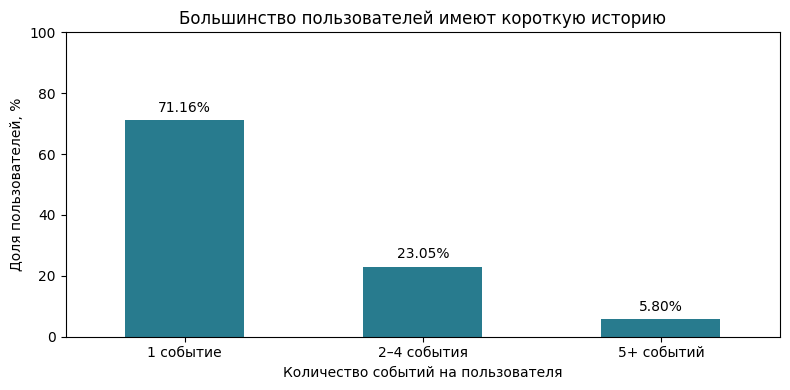

In [21]:
# Доли пользователей с разной активностью
ax = user_activity_pct.plot.bar(
    figsize=(8, 4),
    color='#287B8E',
    rot=0
)

ax.set_title('Большинство пользователей имеют короткую историю')
ax.set_xlabel('Количество событий на пользователя')
ax.set_ylabel('Доля пользователей, %')
ax.set_ylim(0, 100)

# Подписываем процент над каждой колонкой
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=4)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / 'eda_user_activity.png',
    dpi=200,
    bbox_inches='tight'
)
plt.show()                                                                    

In [22]:
# Выбираем события покупки из таблица после удаления дубликатов
purchase_events = events_df[events_df['event'] == 'transaction']

purchases_per_item = purchase_events['itemid'].value_counts()
display(purchases_per_item.describe())

# Сколько редко покупаемых товаров
print('Редко покупаемых товаров:', (purchases_per_item < 5).sum())

# Какой процент товаров имеет меньше пяти покупок
print('Их доля, %:', (purchases_per_item < 5).mean() * 100)

count    12025.000000
mean         1.867526
std          2.710560
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        133.000000
Name: count, dtype: float64

Редко покупаемых товаров: 11360
Их доля, %: 94.46985446985448


In [23]:
# Добавляем все товары из таблицы событий
# Для товаров, отсутствующих в подсчёте покупок, устанавливаем ноль
all_item_purchase_counts = purchases_per_item.reindex(
    events_df['itemid'].unique(),
    fill_value=0
)

In [24]:
# Количество товаров без покупок
items_without_purchase = all_item_purchase_counts[all_item_purchase_counts == 0]

# Считаем количество товаров без покупок
print('Товаров без покупок:', (all_item_purchase_counts == 0).sum())

# Доля товаров без покупок среди всех товаров
print('Их доля, %:', (all_item_purchase_counts == 0).mean() * 100)

# Сколько часто покупаемых товаров
print('Товаров с 5+ покупками:', (all_item_purchase_counts >= 5).sum())

Товаров без покупок: 223036
Их доля, %: 94.88430662679049
Товаров с 5+ покупками: 665


In [25]:
# Какую долю всех покупок обеспечивают эти 665 товаров
purchase_share_5plus_pct = (all_item_purchase_counts[all_item_purchase_counts >= 5].sum() / (all_item_purchase_counts).sum()) * 100

print(f'Доля покупок товаров с 5+ покупками: {purchase_share_5plus_pct:.2f}%')

Доля покупок товаров с 5+ покупками: 25.11%


**Комментарий**
* На 665 товаров с пятью и более покупками приходится 25,11% всех событий покупки. При исключении остальных товаров потеряется около 74,89% событий покупки, поэтому такой порог требует проверки на валидации

In [26]:
# Количество товаров в каждой группе по числу покупок
item_purchase_groups = pd.Series({
    'Без покупок': (all_item_purchase_counts == 0).sum(),
    '1–4 покупки': (
        (all_item_purchase_counts >= 1)
        & (all_item_purchase_counts < 5)
    ).sum(),
    '5+ покупок': (all_item_purchase_counts >= 5).sum()
})

In [27]:
item_purchase_pct = (item_purchase_groups /item_purchase_groups.sum()) * 100
item_purchase_pct

Без покупок    94.884307
1–4 покупки     4.832788
5+ покупок      0.282905
dtype: float64

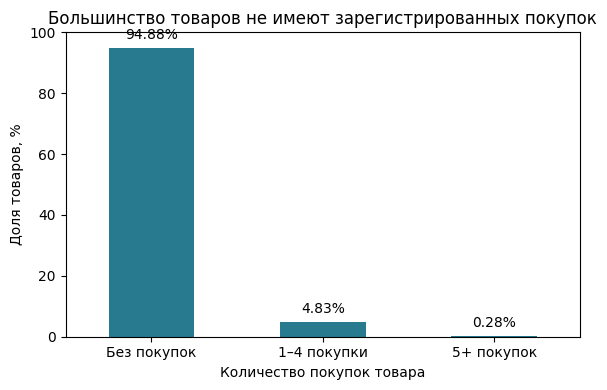

In [28]:
ax = item_purchase_pct.plot.bar(
    figsize=(6, 4),
    color='#287B8E',
    rot=0
)

ax.set_title('Большинство товаров не имеют зарегистрированных покупок')
ax.set_xlabel('Количество покупок товара')
ax.set_ylabel('Доля товаров, %')
ax.set_ylim(0, 100)

# Процент над каждой колонкой
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=4)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / 'eda_item_purchases.png',
    dpi=200,
    bbox_inches='tight'
)
plt.show()

In [29]:
# Идентификаторы пользователей с пятью и более событиями
active_user_ids = events_per_user[events_per_user >= 5].index

# События активных пользователей
active_user_events = events_df[
    events_df['visitorid'].isin(active_user_ids)
]

In [30]:
# Доля сохраненных событий
retained_events_pct = (len(active_user_events) / len(events_df)) * 100

# Доля сохраенных покупок 
retained_purchases_pct = ((active_user_events['event'] == 'transaction').sum() / 
                          len(purchase_events)) * 100

print(f'Сохранено событий: {retained_events_pct:.2f}%')
print(f'Доля сохраенных покупок: {retained_purchases_pct:.2f}%')

Сохранено событий: 34.40%
Доля сохраенных покупок: 81.32%


**Комментарий**
* Фильтрация пользователей с менее чем пятью событиями сохраняет 34,40% взаимодействий и 81,32% событий покупки. Она существенно сокращает объём данных, сохраняя большую часть покупок. Однако улучшение качества рекомендаций необходимо проверить на валидации.

In [31]:
# Товары с пятью и более покупками за наблюдаемый период
frequent_item_ids = all_item_purchase_counts[
    all_item_purchase_counts >= 5
].index

filtered_events_eda = active_user_events[
    active_user_events['itemid'].isin(frequent_item_ids)]

In [32]:
# Доля сохранённых событий
filtered_events_pct = (len(filtered_events_eda) / len(events_df)) * 100 

# Доля сохраненных покупок
filtered_purchases_pct = ((filtered_events_eda['event'] == 'transaction').sum() / 
                          len(purchase_events)) * 100 

In [33]:
print(f'Сохранено событий после двух фильтров: {filtered_events_pct:.2f}%')
print(f'Сохранено покупок после двух фильтров: {filtered_purchases_pct:.2f}%')

Сохранено событий после двух фильтров: 3.61%
Сохранено покупок после двух фильтров: 19.94%


**Комментарий**
* Совместная фильтрация сохраняет лишь 3,61% событий и 19,94% покупок. Порог в пять покупок для товаров существенно сокращает обучающие данные

### **Создание выборок. Train, Validation, Test**

In [34]:
# Находим последнюю дату датасета
max_date = events_df['date'].max()

# Граница VALIDATION и TEST
val_end = max_date - pd.Timedelta(days=TEST_DAYS)

# Граница TRAIN и VALIDATION
train_end = val_end - pd.Timedelta(days=VAL_DAYS)

print(train_end)
print(val_end)
print(max_date)

2015-08-21 02:59:47.788000
2015-09-04 02:59:47.788000
2015-09-18 02:59:47.788000


In [35]:
# Train
train_events = events_df[events_df['date'] < train_end].copy()
train_events.shape

(2262025, 6)

In [36]:
# Validation
val_events = events_df[(events_df['date'] >= train_end) & (events_df['date'] < val_end)].copy()
val_events.shape

(246692, 6)

In [37]:
# Test
test_events = events_df[events_df['date'] >= val_end].copy()
test_events.shape

(246924, 6)

In [38]:
# Сколько событий было изначально 
events_df.shape[0]

2755641

In [39]:
# Сколько событий получилось после разбиения. Проверка
total_events = (
    train_events.shape[0]
    + val_events.shape[0]
    + test_events.shape[0]
)

print(total_events)

2755641


In [40]:
# Проверки разбиения 
assert len(train_events) + len(val_events) + len(test_events) == len(events_df)
assert train_events['date'].max() < val_events['date'].min()
assert val_events['date'].max() < test_events['date'].min()
print('Разбиение корректно: три выборки не пересекаются и покрывают все события')

Разбиение корректно: три выборки не пересекаются и покрывают все события


In [41]:
# Распределение типов событий
dist = pd.DataFrame({
    'train': train_events['event'].value_counts(),
    'val': val_events['event'].value_counts(),
    'test': test_events['event'].value_counts(),
})
dist

,train,val,test
event,,,
view,2187328,238112,238778
addtocart,56215,6502,6249
transaction,18482,2078,1897


**Комментарий**
* Распределение типов событий достаточно похоже во всех трёх периодах
* Покупки редки по сравнению с просмотрами

In [42]:
# Покупатели в VALIDATION
val_buyers = val_events[
    val_events['event'] == 'transaction'
]

# Количество уникальных покупателей
val_buyers['visitorid'].nunique()

1131

In [43]:
# Уникальные пользователи обучающей выборки
train_users = train_events['visitorid'].unique()

# Уникальные покупатели VALIDATION 
val_buyer_ids = val_buyers['visitorid'].drop_duplicates()
# Для каждого покупателя: есть ли он среди пользователей train?
val_known_buyers = val_buyer_ids.isin(set(train_users))        

total = len(val_buyer_ids)
known = int(val_known_buyers.sum())                            
new = total - known                                            

print(f"Известные: {known} ({known / total:.1%})")
print(f"Новые (Cold Start): {new} ({new / total:.1%})")

Известные: 193 (17.1%)
Новые (Cold Start): 938 (82.9%)


**Комментарий**
* Примерно 83% покупателей в VALIDATION - новые пользователи (938 из 1131); известных - 193 (17%)

In [44]:
# Уникальные товары обучающей выборки
train_items = train_events['itemid'].unique()

# Уникальные купленные товары в VALIDATION
val_purchased_items = val_buyers['itemid'].unique()

# Проверяем, какие товары из VALIDATION встречались в TRAIN
val_known_items = pd.Series(val_purchased_items).isin(train_items)
len(val_purchased_items)

1614

In [45]:
# Количество известных товаров
val_known_items.sum()

np.int64(1572)

In [46]:
# Количество новых товаров
(~val_known_items).sum()

np.int64(42)

In [47]:
# Сколько событий покупки в VALIDATION приходится на товары, известные в TRAIN
val_known_item_transactions = (
    val_buyers['itemid'].isin(train_items)
    .sum()
)

print(val_known_item_transactions)

2033


**Комментарий**
* Вывод: только 2,17% событий покупки приходится на товары, которых вообще не было в TRAIN
Это хорошо с точки зрения рекомендательной системы: большинство покупок относятся к товарам, по которым уже имеется история взаимодействий
* Но наличие товара в TRAIN не означает, что его обязательно покупали. Он мог присутствовать только в просмотрах

In [48]:
# "Потолок" персональной модели - какая доля покупок validation приходится на товары,
# с которыми ЭТОТ ЖЕ пользователь уже взаимодействовал в train
train_pairs = train_events[['visitorid', 'itemid']].drop_duplicates()
val_pairs = val_buyers[['visitorid', 'itemid']].drop_duplicates()
merged_pairs = val_pairs.merge(train_pairs, how='left', indicator=True)       # indicator добавляет столбец _merge
repeat_share = (merged_pairs['_merge'] == 'both').mean()
print(f'Покупки (пары покупатель-товар), где у пользователя уже была история с этим товаром: {repeat_share:.1%}')
del train_pairs, val_pairs, merged_pairs

Покупки (пары покупатель-товар), где у пользователя уже была история с этим товаром: 5.9%


**Комментарий**
* Всего в validation около 1978 пар "покупатель - товар". Только примерно 5,9% из них такие, где человек уже взаимодействовал с этим товаром в train. Остальные 94% это покупки товара, которого у этого человека в истории не было, или покупки людей без истории вообще

### **Признаки пользователя**

In [49]:
# ГРАНИЦА ОТСЕЧЕНИЯ. Факторы считаем только по событиям до неё,
# чтобы в факторы не попали данные из периода, который мы потом предсказываем
#   этап validation:  FEATURE_CUTOFF = train_end  -> история = train,            таргет берём из validation
#   финальный тест:   FEATURE_CUTOFF = val_end    -> история = train + validation, таргет берём из test
FEATURE_CUTOFF = train_end

cutoff = FEATURE_CUTOFF
hist = events_df[events_df['date'] < cutoff].copy()

print('Граница отсечения:', FEATURE_CUTOFF)
print('Событий в истории:', train_events.shape[0], 'из', events_df.shape[0])
print('Последнее событие в истории:',train_events['date'].max())

Граница отсечения: 2015-08-21 02:59:47.788000
Событий в истории: 2262025 из 2755641
Последнее событие в истории: 2015-08-21 02:59:46.322000


In [50]:
# Общее количество событий каждого пользователя в обучающей истории
train_events_per_user = hist.groupby('visitorid').size()

In [51]:
# Количество пользователей с менее чем пятью событиями в обучающей истории
train_inactive_users_count = (train_events_per_user < 5).sum()

# Их доля среди пользователей обучающей истории, в процентах
train_inactive_users_pct = (train_events_per_user < 5).mean() * 100

print(f'Малоактивных пользователей: {train_inactive_users_count}')
print(f'Их доля: {train_inactive_users_pct:.2f}%')

Малоактивных пользователей: 1085474
Их доля: 94.16%


In [52]:
# Оставляем только покупки из обучающей истории
train_purchase_events = hist[hist['event'] == 'transaction']

# Считаем количество покупок каждого товара
train_purchases_per_item = train_purchase_events['itemid'].value_counts()

# Показываем пять самых часто покупаемых товаров
train_purchases_per_item.head()

itemid
461686    96
119736    77
213834    61
445351    43
48030     41
Name: count, dtype: int64

In [53]:
# Добавляем подсчёт всеми товарами из обучающей истории
train_purchases_per_item = train_purchases_per_item.reindex( # Приводит подсчёт к этому списку
    hist['itemid'].unique(), # Все уникальные товары обучающей истории
    fill_value=0 # Ставит ноль товарам без покупок. Уже посчитанные покупки сохраняются.
)
 
# Количество товаров с пятью и более покупками в обучающей истории
train_items_5plus_count = (train_purchases_per_item >= 5).sum()
print(train_items_5plus_count) 

520


**Комментарий**
* 520 товаров имеют пять и более покупок в обучающей истории. Именно этот список можно использовать для фильтрации при оценке на validation

In [54]:
# Идентификаторы товаров с пятью и более покупками в обучающей истории
train_frequent_item_ids = train_purchases_per_item[
    train_purchases_per_item >= 5
].index

train_active_user_ids = train_events_per_user[train_events_per_user >= 5].index

In [55]:
# Пользователь входит в список активных
user_mask = hist['visitorid'].isin(train_active_user_ids)

# Товар входит в список достаточно часто покупаемых
item_mask = hist['itemid'].isin(train_frequent_item_ids)

# Оставляем строки, где подходят и пользователь, и товар
hist_filtered = hist[user_mask & item_mask].copy()

print('Событий до фильтрации:', len(hist))
print('Событий после фильтрации:', len(hist_filtered))

Событий до фильтрации: 2262025
Событий после фильтрации: 72367


In [56]:
# Отбираем покупки из валидационной выборки
val_purchases = val_events[val_events['event'] == 'transaction'].copy()

print('Событий покупки:', len(val_purchases))

Событий покупки: 2078


In [57]:
# Количество уникальных пользователей в valide
val_buyers_count = val_purchases['visitorid'].nunique()
print('Количество уникальных пользователей в валидационной выборке:',val_buyers_count)

Количество уникальных пользователей в валидационной выборке: 1131


In [58]:
# Проверяем, есть ли события в валидационной выборке
print('Событий в validation:', len(val_events))
print()
# Проверяем типы событий и наличие покупок
print(val_events['event'].value_counts())
print()
# Проверяем размер отобранной таблицы покупок
print('Строк в val_purchases:', len(val_purchases))

Событий в validation: 246692

event
view           238112
addtocart        6502
transaction      2078
Name: count, dtype: int64

Строк в val_purchases: 2078


In [59]:
# Для каждого покупателя собираем уникальные товары, купленные в validation
val_targets = val_purchases.groupby('visitorid')['itemid'].agg(set)

# Показываем первые пять покупателей и их товары
val_targets.head()

visitorid
3936    {172894}
6618     {49967}
7773    {414831}
8411    {392689}
9155    {431290}
Name: itemid, dtype: object

In [60]:
# Считаем количество каждого типа события для каждого пользователя
user_features = hist.groupby(['visitorid', 'event']).size().unstack().fillna(0)

# Считаем количество уникальных товаров, с которыми взаимодействовал каждый пользователь
user_unique_items = hist.groupby('visitorid')['itemid'].nunique()
user_features['unique_items'] = user_unique_items

In [61]:
# Сглаживание конверсии для пользователей
prior = user_features['transaction'].sum() / user_features['view'].sum()
alpha = 5  # сила сглаживания
user_features['conversion'] = (
    (user_features['transaction'] + alpha * prior) / (user_features['view'] + alpha)
).clip(upper=1)

In [62]:
# Количество уникальных дней, в которые пользователь проявлял активность на сайте интернет-магазина
user_features['user_active_days'] = (hist.assign(day=hist['date'].dt.normalize()).groupby('visitorid')['day'].nunique())

In [63]:
# Сколько дней прошло с момента последней активности каждого пользователя
user_features['user_recency_days'] = ((cutoff - hist.groupby('visitorid')['date'].max()).dt.total_seconds() / 86400)

In [64]:
# user_views_7d — сколько раз пользователь просматривал товары за последние 7 дней
# user_views_30d — сколько раз пользователь просматривал товары за последние 30 дней

views = hist.loc[hist['event'].eq('view')]

for days in (7, 30):
    recent = views.loc[
        views['date'] >= cutoff - pd.Timedelta(days=days)]
    user_features[f'user_views_{days}d'] = (
        recent.groupby('visitorid').size().reindex(user_features.index, fill_value=0)
        )

In [65]:
# Покупка без просмотра
user_features['bought_without_view'] = ((user_features['view'] == 0) & (user_features['transaction'] > 0)).astype(int)

### **Признаки товара**

In [66]:
# Создаём признаки товаров: считаем количество каждого типа события для каждого товара
item_features = (
    hist.groupby(['itemid', 'event'])
    .size()
    .unstack()
    .fillna(0)
)

In [67]:
# сколько уникальных пользователей взаимодействовало с каждым товаром
item_unique_users = hist.groupby('itemid')['visitorid'].nunique()

# Добавляем количество уникальных пользователей для каждого товара
item_features['unique_users'] = item_unique_users

**Комментарий**
* У товаров без просмотров конверсия и доля добавлений в корзину дают NaN (0 / 0) и inf (число / 0)
* Применяем то же сглаживание, что и для конверсии пользователей: без NaN и inf, а товары с малой историей тянутся к средним значениям по магазину

In [68]:
# Сила сглаживания
alpha = 5  

# Признак: у товара нет ни одного зарегистрированного просмотра
item_features['item_no_views'] = (item_features['view'] == 0).astype(int)

conv_prior = item_features['transaction'].sum() / item_features['view'].sum()
cart_prior = item_features['addtocart'].sum() / item_features['view'].sum()

item_features['item_conversion'] = (
    (item_features['transaction'] + alpha * conv_prior) / (item_features['view'] + alpha)
).clip(upper=1)

item_features['cart_rate'] = (
    (item_features['addtocart'] + alpha * cart_prior) / (item_features['view'] + alpha)
).clip(upper=1)

# Проверка: NaN и inf не осталось
check_cols = ['item_conversion', 'cart_rate']
print('NaN:', item_features[check_cols].isna().sum().sum(),
      '| inf:', np.isinf(item_features[check_cols]).sum().sum())

NaN: 0 | inf: 0


In [69]:
def count_in_window(events, cutoff, days, event, key='itemid'):
    """Сколько событий типа event 
    было у каждого key 
    за последние `days` дней 
    перед границей cutoff"""
    window = events[(events['date'] >= cutoff - pd.Timedelta(days=days)) & (events['event'] == event)]
    return window.groupby(key).size()

for days in (30, 7):
    item_features[f'transactions_{days}d'] = (
        count_in_window(hist, cutoff, days, 'transaction').reindex(item_features.index, fill_value=0))
    print(f'transactions_{days}d: пропусков', item_features[f'transactions_{days}d'].isna().sum())

transactions_30d: пропусков 0
transactions_7d: пропусков 0


In [70]:
item_features.head()

event,addtocart,transaction,view,unique_users,item_no_views,item_conversion,cart_rate,transactions_30d,transactions_7d
itemid,,,,,,,,,
3,0.0,0.0,1.0,1,0,0.007041,0.021417,0,0
4,0.0,0.0,1.0,1,0,0.007041,0.021417,0,0
6,0.0,0.0,28.0,25,0,0.001280,0.003894,0,0
9,0.0,0.0,2.0,2,0,0.006035,0.018357,0,0
15,3.0,1.0,18.0,13,0,0.045315,0.136022,0,0


In [71]:
# Сколько дней прошло с последнего взаимодействия с товаром (recency)
# чем меньше recency, тем свежее активность товара

# Находим дату последнего взаимодействия с каждым товаром
item_last_event = hist.groupby('itemid')['date'].max()

# Считаем, сколько времени прошло с последнего взаимодействия
item_recency = cutoff - item_last_event

In [72]:
item_recency.head()

itemid
3     2 days 08:29:07.295000
4    51 days 19:56:36.243000
6     0 days 16:42:50.449000
9    43 days 01:24:39.473000
15   31 days 02:56:48.259000
Name: date, dtype: timedelta64[ns]

In [73]:
item_features['recency_days'] = item_recency.dt.total_seconds() / 86400
item_features['recency_days'].isna().sum()

np.int64(0)

In [74]:
item_features.describe()

event,addtocart,transaction,view,unique_users,item_no_views,item_conversion,cart_rate,transactions_30d,transactions_7d,recency_days
count,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000,215521.000000
mean,0.260833,0.085755,10.149025,8.155688,0.000877,0.007111,0.022384,0.023339,0.005201,34.848222
std,1.600721,0.641116,30.467321,23.193867,0.029600,0.012790,0.029667,0.266342,0.090192,30.731510
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000020,0.000077,0.000000,0.000000,0.000017
25%,0.000000,0.000000,1.000000,1.000000,0.000000,0.003841,0.012850,0.000000,0.000000,8.253309
50%,0.000000,0.000000,3.000000,2.000000,0.000000,0.006035,0.018357,0.000000,0.000000,25.971112
75%,0.000000,0.000000,8.000000,7.000000,0.000000,0.007041,0.021417,0.000000,0.000000,55.467702
max,231.000000,96.000000,2145.000000,1924.000000,1.000000,0.880281,1.000000,48.000000,11.000000,109.997941


**Комментарий**
* Transaction - у 75% товаров число покупок равно нулю. При этом некоторые товары покупали десятки и даже до 96 раз. То есть покупки распределены очень неравномерно - есть большое количество товаров без покупок и небольшая группа значительно более популярных товаров
* Товары очень неравномерны по популярности - popularity bias / long tail
* recency_days - медиана 32 означает: примерно половина товаров последний раз встречалась в событиях не более 32 дней назад, а другая половина - не менее 32 дней назад

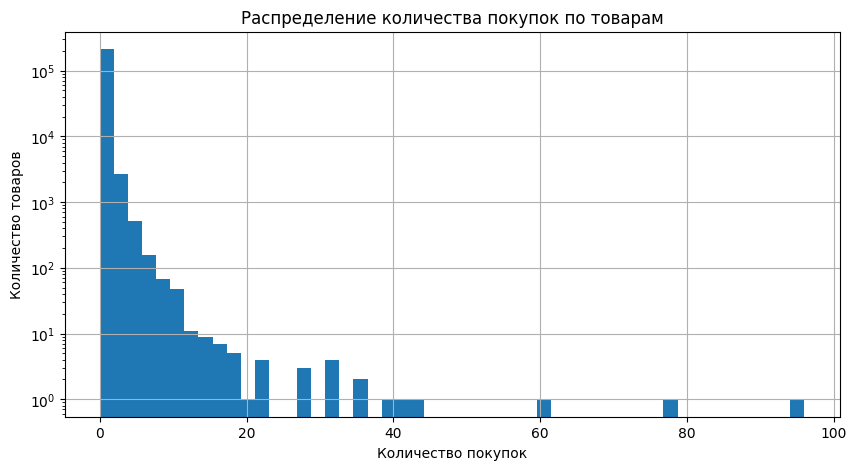

In [75]:
item_features['transaction'].hist(
    bins=50,
    figsize=(10, 5)
)

plt.xlabel('Количество покупок')
plt.ylabel('Количество товаров')
plt.title('Распределение количества покупок по товарам')

plt.yscale('log')

plt.show()

In [76]:
# TOP-20 товаров по количеству покупок
top_20_items = item_features['transaction'].nlargest(20)
top_20_items

itemid
461686    96.0
119736    77.0
213834    61.0
445351    43.0
48030     41.0
7943      40.0
17478     36.0
420960    35.0
46156     31.0
312728    31.0
369447    31.0
416017    31.0
257040    27.0
409804    27.0
441852    27.0
37029     23.0
268883    23.0
318333    23.0
248455    22.0
9877      20.0
Name: transaction, dtype: float64

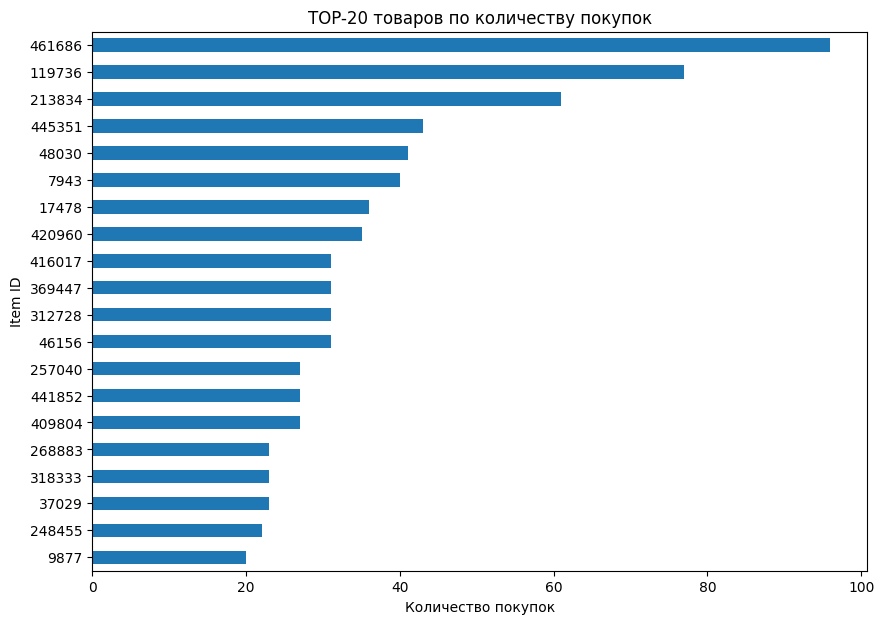

In [77]:
# TOP-20 товаров по количеству покупок. Визуализация
top_20_items.sort_values().plot(kind='barh', figsize=(10,7))

plt.xlabel('Количество покупок')
plt.ylabel('Item ID')
plt.title('TOP-20 товаров по количеству покупок')

plt.show()

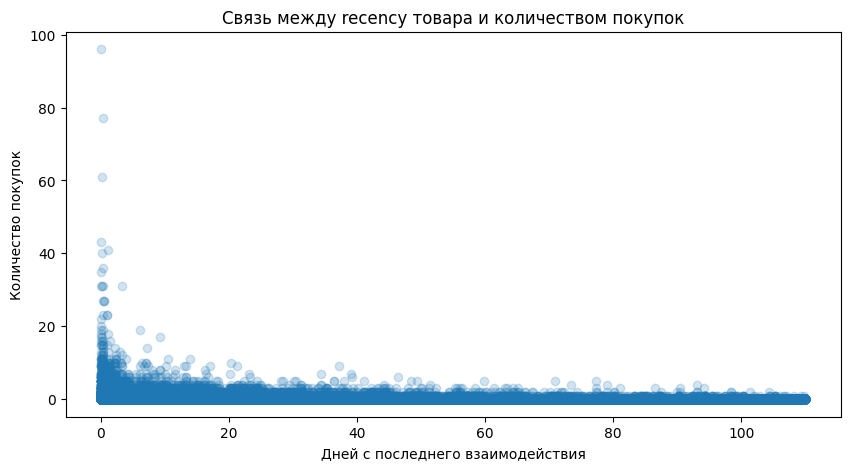

In [78]:
# Связь между давностью последней активности и количеством покупок товара
plt.figure(figsize=(10, 5))

plt.scatter(
    item_features['recency_days'],
    item_features['transaction'],
    alpha=0.2 # прозрачность точек
    )

plt.xlabel('Дней с последнего взаимодействия')
plt.ylabel('Количество покупок')
plt.title('Связь между recency товара и количеством покупок')

plt.show()

In [79]:
# Товары, у которых была хотя бы одна покупка
purchased_items = item_features[item_features['transaction'] > 0]

# Корреляция между recency и количеством покупок
purchased_items[['recency_days', 'transaction']].corr(method='spearman')

event,recency_days,transaction
event,,
recency_days,1.000000,-0.221282
transaction,-0.221282,1.000000


**Комментарий**
* чем больше дней прошло с последнего взаимодействия с товаром, тем меньше у него покупок
* recency_days имеет смысл оставить как признак, но нельзя ожидать, что он один хорошо объяснит покупки

### **Признаки пары Пользователь-Товар**

In [80]:
def create_user_item_features(events, cutoff):
    # Считаем количество каждого типа события для каждой пары пользователь-товар
    user_item_features = (events.groupby(['visitorid', 'itemid', 'event'])
                          .size().unstack(fill_value=0)
                          .reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0))

    # Считаем общее количество взаимодействий пользователя с товаром
    user_item_features['total_interactions'] = (
        user_item_features[['view', 'addtocart', 'transaction']].sum(axis=1))

    # Когда пользователь последний раз взаимодействовал именно с этим товаром
    user_item_features['last_interaction'] = (events.groupby(['visitorid', 'itemid'])
                                             ['date'].max())

    # Считаем, сколько времени прошло с последнего взаимодействия
    user_item_features['user_item_recency'] = (
        cutoff - user_item_features['last_interaction'])

    # Переводим время с последнего взаимодействия в ДРОБНЫЕ дни
    user_item_features['user_item_recency_days'] = (
        user_item_features['user_item_recency'].dt.total_seconds() / 86400)

    # Взвешенная сила интереса: веса те же, что в выбранной модели
    user_item_features['interaction_score'] = sum(
        user_item_features[event] * weight for event, weight in EVENT_WEIGHTS.items())

    return user_item_features

In [81]:
user_item_features = create_user_item_features(hist, cutoff)
user_item_features.head()

event             view  addtocart  transaction  total_interactions  \
visitorid itemid                                                     
1         72028      1          0            0                   1   
2         216305     2          0            0                   2   
          259884     1          0            0                   1   
          325215     3          0            0                   3   
          342816     2          0            0                   2   

event                   last_interaction       user_item_recency  \
visitorid itemid                                                   
1         72028  2015-08-13 17:46:06.444  7 days 09:13:41.344000   
2         216305 2015-08-07 18:17:43.170 13 days 08:42:04.618000   
          259884 2015-08-07 17:56:52.664 13 days 09:02:55.124000   
          325215 2015-08-07 18:20:57.845 13 days 08:38:49.943000   
          342816 2015-08-07 18:17:24.375 13 days 08:42:23.413000   

event             user_item_recency_days  interaction_score  
visitorid itemid                                             
1         72028                 7.384506                  1  
2         216305               13.362553                  2  
          259884               13.377027                  1  
          325215               13.360300                  3  
          342816               13.362771                  2

In [82]:
user_item_features.describe()

event,view,addtocart,transaction,total_interactions,last_interaction,user_item_recency,user_item_recency_days,interaction_score
count,1.757722e+06,1.757722e+06,1.757722e+06,1.757722e+06,1757722,1757722,1.757722e+06,1.757722e+06
mean,1.244411e+00,3.198174e-02,1.051475e-02,1.286907e+00,2015-06-27 08:40:17.098131200,54 days 18:19:30.689869043,5.476355e+01,1.562041e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2015-05-03 03:00:11.289000,0 days 00:00:01.466000,1.696759e-05,1.000000e+00
25%,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2015-05-30 22:18:24.072749824,27 days 20:19:06.811500,2.784661e+01,1.000000e+00
50%,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2015-06-28 17:09:52.122000128,53 days 09:49:55.666000,5.340967e+01,1.000000e+00
75%,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2015-07-24 06:40:40.976499968,82 days 04:41:23.715250,8.219541e+01,1.000000e+00
max,3.080000e+02,3.100000e+01,7.000000e+00,3.080000e+02,2015-08-21 02:59:46.322000,109 days 23:59:36.499000,1.099997e+02,3.080000e+02
std,1.147077e+00,2.094081e-01,1.083198e-01,1.216502e+00,NaN,31 days 07:51:08.540440378,3.132718e+01,2.724691e+00


**Комментарий**
* 1 757 722 уникальных пар visitorid + itemid
* 3 признака: addtocart, transaction, view
* По первым строкам хорошо видно MultiIndex: пользователь 2 просмотрел товар 216305 два раза

In [83]:
# Сколько секунд прошло между текущим событием пользователя и его предыдущим событием

# Сортируем события каждого пользователя по времени
events_sorted = hist.sort_values(['visitorid', 'date']).copy()
events_sorted[['visitorid', 'itemid', 'event', 'date']].head(10)

,visitorid,itemid,event,date
830254,1,72028,view,2015-08-13 17:46:06.444
742509,2,325215,view,2015-08-07 17:51:44.567
735167,2,325215,view,2015-08-07 17:53:33.790
737605,2,259884,view,2015-08-07 17:56:52.664
726186,2,216305,view,2015-08-07 18:01:08.920
737509,2,342816,view,2015-08-07 18:08:25.669
735096,2,342816,view,2015-08-07 18:17:24.375
742378,2,216305,view,2015-08-07 18:17:43.170
728182,2,325215,view,2015-08-07 18:20:57.845
612302,3,385090,view,2015-08-01 07:10:35.296


In [84]:
# Считаем время между текущим и предыдущим событием пользователя
events_sorted['time_since_prev_event'] = (events_sorted.groupby('visitorid')['date'].diff())

In [85]:
# Переводим время между событиями в секунды
events_sorted['time_since_prev_event_sec'] = (events_sorted['time_since_prev_event'].dt.total_seconds())

In [86]:
# Оставляем только просмотры товаров
view_events = events_sorted[events_sorted['event'] == 'view'].copy()

# Считаем время между текущим и предыдущим просмотром пользователя
view_events['time_since_prev_view_sec'] = (
    view_events.groupby('visitorid')['date']
    .diff()
    .dt.total_seconds()
)

In [87]:
view_events['time_since_prev_view_sec'].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

count    1.037136e+06
mean     1.792921e+05
std      7.335126e+05
min      0.000000e+00
10%      1.459700e+01
25%      3.967900e+01
50%      1.446080e+02
75%      2.890612e+03
90%      2.560477e+05
max      9.363715e+06
Name: time_since_prev_view_sec, dtype: float64

**Комментарий**
* ≈15 секунд как первоначальный порог быстрого перехода, потому что это примерно нижние 10% интервалов
* Но одного такого перехода недостаточно, чтобы объявить пользователя "бессмысленно листающим". Он мог просто быстро открыть один товар
* Товары должны быть разными. Если пользователь пять раз открыл один и тот же товар, это, наоборот, может быть сильным интересом

In [88]:
# Определяем предыдущий просмотренный товар пользователя
view_events['prev_itemid'] = (view_events.groupby('visitorid')['itemid'].shift(1))

In [89]:
# Определяем порог быстрого перехода как 10-й процентиль
rapid_threshold = view_events['time_since_prev_view_sec'].quantile(0.10)

rapid_threshold

np.float64(14.597)

In [90]:
view_events['is_rapid_transition'] = (
    (view_events['time_since_prev_view_sec'] <= rapid_threshold)
    &
    (view_events['itemid'] != view_events['prev_itemid'])
)

In [91]:
view_events['is_rapid_transition'].mean()

np.float64(0.036976164525850716)

**Комментарий**
* Это означает, что примерно 3,7% всех просмотров являются быстрыми переходами на другой товар по нашему текущему правилу


In [92]:
# Считаем общее количество просмотров каждой пары юзер-айтем
user_item_view_count = (
    view_events.groupby(['visitorid', 'itemid'])
    .size()
)

user_item_view_count.head()

visitorid  itemid
1          72028     1
2          216305    2
           259884    1
           325215    3
           342816    2
dtype: int64

In [93]:
# Создаём номер последовательности просмотров для каждого пользователя
view_events['rapid_sequence_id'] = (
    (~view_events['is_rapid_transition'])
    .groupby(view_events['visitorid'])
    .cumsum()
)

In [94]:
# Считаем количество быстрых переходов в каждой последовательности
rapid_sequence_size = (
    view_events.groupby(
        ['visitorid', 'rapid_sequence_id']
    )['is_rapid_transition'].sum())

In [95]:
rapid_sequence_size.describe()

count    2.106449e+06
mean     3.839590e-02
std      3.003458e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.200000e+01
Name: is_rapid_transition, dtype: float64

**Комментарий**
* В датасете есть как минимум одна непрерывная цепочка из 52 быстрых переходов подряд

In [96]:
# Оставляем последовательности минимум из 3 быстрых переходов подряд
rapid_sequences = rapid_sequence_size[
    rapid_sequence_size >= 3
]

rapid_sequences.shape

(4586,)

In [97]:
# Для каждой строки указываем, сколько быстрых переходов было в её последовательности
view_events['rapid_sequence_size'] = (view_events.groupby(['visitorid', 'rapid_sequence_id'])['is_rapid_transition'].transform('sum'))

In [98]:
# Помечаем все просмотры, входящие в rapid-browsing последовательность
view_events['is_rapid_browsing'] = (
    view_events['rapid_sequence_size'] >= 3
)

view_events['is_rapid_browsing'].sum()

np.int64(23962)

In [99]:
view_events['is_rapid_browsing'].mean()

np.float64(0.010954918512449893)

**Комментарий**
* 23 962 просмотров относятся к найденным rapid-browsing последовательностям, то есть примерно 1,10% всех просмотров
* Было обнаружено 4586 отдельных эпизодов rapid browsing, в каждом из которых было минимум 3 быстрых перехода подряд.
Причём один эпизод из 3 переходов соответствует примерно 4 быстро просмотренным товарам

In [100]:
# Считаем количество просмотров в режиме rapid browsing для каждой пары пользователь-товар
rapid_browsing_count = (
    view_events.groupby(['visitorid', 'itemid'])
    ['is_rapid_browsing']
    .sum()
)

# Считаем долю rapid-browsing просмотров для каждой пары пользователь-товар
rapid_browsing_ratio = (
    rapid_browsing_count / user_item_view_count
)

In [101]:
rapid_browsing_ratio.describe()

count    1.747605e+06
mean     9.482511e-03
std      9.321337e-02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e+00
dtype: float64

In [102]:
# Добавляем долю rapid-browsing просмотров для каждой пары пользователь-товар
user_item_features['rapid_browsing_ratio'] = rapid_browsing_ratio

user_item_features['rapid_browsing_ratio'].isna().sum()

np.int64(10117)

In [103]:
# Для пар без просмотров rapid browsing отсутствует
user_item_features['rapid_browsing_ratio'] = (
    user_item_features['rapid_browsing_ratio'].fillna(0)
)

user_item_features['rapid_browsing_ratio'].isna().sum()

np.int64(0)

Сколько времени прошло от просмотра товара до следующего действия этого же пользователя ->

In [104]:
# Находим время следующего события каждого пользователя
events_sorted['next_event_date'] = (events_sorted.groupby('visitorid')['date'].shift(-1))

In [105]:
# Считаем время от текущего события до следующего события пользователя
events_sorted['time_to_next_event'] = (
    events_sorted['next_event_date'] - events_sorted['date']
)

# Переводим интервал в секунды
events_sorted['time_to_next_event_sec'] = (
    events_sorted['time_to_next_event']
    .dt.total_seconds()
)

events_sorted.head(15)

,timestamp,visitorid,event,itemid,transactionid,date,time_since_prev_event,time_since_prev_event_sec,next_event_date,time_to_next_event,time_to_next_event_sec
830254,1439487966444,1,view,72028,NaN,2015-08-13 17:46:06.444,NaT,NaN,NaT,NaT,NaN
742509,1438969904567,2,view,325215,NaN,2015-08-07 17:51:44.567,NaT,NaN,2015-08-07 17:53:33.790,0 days 00:01:49.223000,109.223
735167,1438970013790,2,view,325215,NaN,2015-08-07 17:53:33.790,0 days 00:01:49.223000,109.223,2015-08-07 17:56:52.664,0 days 00:03:18.874000,198.874
737605,1438970212664,2,view,259884,NaN,2015-08-07 17:56:52.664,0 days 00:03:18.874000,198.874,2015-08-07 18:01:08.920,0 days 00:04:16.256000,256.256
726186,1438970468920,2,view,216305,NaN,2015-08-07 18:01:08.920,0 days 00:04:16.256000,256.256,2015-08-07 18:08:25.669,0 days 00:07:16.749000,436.749
737509,1438970905669,2,view,342816,NaN,2015-08-07 18:08:25.669,0 days 00:07:16.749000,436.749,2015-08-07 18:17:24.375,0 days 00:08:58.706000,538.706
735096,1438971444375,2,view,342816,NaN,2015-08-07 18:17:24.375,0 days 00:08:58.706000,538.706,2015-08-07 18:17:43.170,0 days 00:00:18.795000,18.795
742378,1438971463170,2,view,216305,NaN,2015-08-07 18:17:43.170,0 days 00:00:18.795000,18.795,2015-08-07 18:20:57.845,0 days 00:03:14.675000,194.675
728182,1438971657845,2,view,325215,NaN,2015-08-07 18:20:57.845,0 days 00:03:14.675000,194.675,NaT,NaT,NaN
612302,1438413035296,3,view,385090,NaN,2015-08-01 07:10:35.296,NaT,NaN,NaT,NaT,NaN


In [106]:
# Оставляем только события просмотра товаров
view_duration = events_sorted[events_sorted['event'] == 'view'].copy()

In [107]:
# Смотрим распределение времени от просмотра до следующего действия
view_duration['time_to_next_event_sec'].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.050994e+06
mean     1.741275e+05
std      7.242328e+05
min      0.000000e+00
10%      1.341300e+01
25%      3.691500e+01
50%      1.304900e+02
75%      2.311798e+03
90%      2.407242e+05
95%      9.688179e+05
99%      4.168578e+06
max      9.363715e+06
Name: time_to_next_event_sec, dtype: float64

**Комментарий**

* У 25% просмотров следующее действие пользователя происходило менее чем примерно через 37 секунд
* У половины наблюдений следующее действие произошло менее чем через 2 минуты 10 секунд
* Среднее - около 2.0 дня - есть пользователи, которые сделали просмотр, а следующее событие произошло через несколько дней или даже месяцев (max - 108 дней)
* 0-30 минут - можно использовать как приблизительное время просмотра
* 30 минут - неизвестно, пользователь, вероятно, ушёл

In [108]:
# Оставляем только реалистичные интервалы внутри активной сессии
view_duration['valid_view_duration_sec'] = (
    view_duration['time_to_next_event_sec']
    .where(view_duration['time_to_next_event_sec'] <= 30 * 60)
)

In [109]:
view_duration['valid_view_duration_sec'].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

count    777504.000000
mean        183.552365
std         300.188465
min           0.000000
10%          10.138300
25%          25.672000
50%          66.480000
75%         184.096500
90%         508.697800
max        1799.922000
Name: valid_view_duration_sec, dtype: float64

In [110]:
is_short = (view_duration['valid_view_duration_sec'] <= 10).astype(float)
view_duration['is_short_view'] = is_short.where(view_duration['valid_view_duration_sec'].notna())

# Доля коротких просмотров для каждой пары пользователь-товар
short_view_ratio = (
    view_duration.groupby(['visitorid', 'itemid'])['is_short_view']
    .mean()
)

In [111]:
user_item_features['short_view_ratio'] = short_view_ratio

In [112]:
# Медианная длительность просмотра товара конкретным пользователем
median_view_duration = (
    view_duration.groupby(['visitorid', 'itemid'])['valid_view_duration_sec']
    .median()
)

user_item_features['median_view_duration'] = median_view_duration

In [113]:
user_item_features[['short_view_ratio', 'median_view_duration']].isna().sum()

event
short_view_ratio        1168361
median_view_duration    1168361
dtype: int64

In [114]:
# Сколько пар имеют рассчитанную валидную длительность
user_item_features['median_view_duration'].notna().sum()

np.int64(589361)

In [115]:
# 1 - длительность удалось рассчитать, 0 - длительность неизвестна
user_item_features['has_view_duration'] = (
    user_item_features['median_view_duration']
    .notna()
    .astype(int)
)

In [116]:
# Освобождаем память (~1 ГБ) - эти таблицы дальше не нужны: нужные признаки уже перенесены в user_item_features
del events_sorted, view_events, view_duration                       # большие таблицы событий с вспомогательными столбцами
del rapid_browsing_count, rapid_browsing_ratio, user_item_view_count # промежуточные результаты rapid browsing
del short_view_ratio, median_view_duration, views, recent            # промежуточные результаты длительности и окон
import gc
gc.collect()

3612

### **Валидация факторов**

In [117]:
# Проверка на утечку данных
assert hist['date'].max() < cutoff

# Проверка количества событий
for event in ['view', 'addtocart', 'transaction']:
    expected = (hist['event'] == event).sum()

    for features in [user_features, item_features,
                     user_item_features]:
        assert features[event].sum() == expected

# Проверка количества пользователей, товаров и пар
assert len(user_features) == hist['visitorid'].nunique()
assert len(item_features) == hist['itemid'].nunique()
assert len(user_item_features) == (
    hist[['visitorid', 'itemid']].drop_duplicates().shape[0]
)

# Проверка временных признаков
for features, column in [
    (user_features, 'user_recency_days'),
    (item_features, 'recency_days'),
    (user_item_features, 'user_item_recency_days')
]:
    assert (features[column] >= 0).all()

# Проверка окон 7 и 30 дней
for d in [7, 30]:
    window = hist[
        hist['date'] >= cutoff - pd.Timedelta(days=d)
    ]

    assert user_features[f'user_views_{d}d'].sum() == (
        window['event'] == 'view'
    ).sum()

    assert item_features[f'transactions_{d}d'].sum() == (
        window['event'] == 'transaction'
    ).sum()

# Проверка NaN и inf
for features in [user_features, item_features]:
    numeric = features.select_dtypes(include='number')

    assert not numeric.isna().any().any()
    assert np.isfinite(numeric.to_numpy()).all()

# Для пар проверяем inf и смотрим NaN отдельно
numeric = user_item_features.select_dtypes(include='number')

assert not np.isinf(
    numeric.to_numpy(dtype=float, na_value=np.nan)
).any()

print(numeric.isna().sum()[lambda x: x > 0])

event
short_view_ratio        1168361
median_view_duration    1168361
dtype: int64


In [118]:
# Дополнительные проверки диапазонов признаков 
assert user_item_features['rapid_browsing_ratio'].between(0, 1).all()
assert user_item_features['short_view_ratio'].dropna().between(0, 1).all()
assert user_features['conversion'].between(0, 1).all()
assert item_features['item_conversion'].between(0, 1).all()
print('Диапазоны признаков корректны')

Диапазоны признаков корректны


## **Эксперименты моделей**
### **Базовая модель: популярные товары**

In [119]:
def pair_scores(events, weights):
    """Сумма весов событий по каждой паре (пользователь, товар)"""
    weight = events['event'].map(weights)
    return weight.groupby([events['visitorid'], events['itemid']]).sum()


def make_personal_recommender(scores, known_users, popular, k=K):
    """Возвращает функцию recommend(user_id): 
        свои лучшие товары по scores + 
        популярные для добора"""
    known = set(known_users)                    
    popular = list(popular)

    def recommend(user_id):
        if user_id in known:
            recs = scores.loc[user_id].sort_values(ascending=False).head(k).index.tolist()
        else:
            recs = []                           # новый пользователь: начинаем с пустого списка
        for item_id in popular:
            if len(recs) >= k:
                break                           # набрано k товаров
            if item_id not in recs:             # без повторов
                recs.append(item_id)
        return recs
    return recommend


def precision_list(recommend, targets, k=K):
    """Precision@k для каждого покупателя: 
    targets - 
    Series пользователь -> множество купленных товаров"""
    return [len(set(recommend(user_id)) & items) / k for user_id, items in targets.items()]


def precision_of_fixed_items(items, targets, k=K):
    """Precision@k, 
    если ВСЕМ рекомендованы одни и те же товары 
    (модель популярности)"""
    items = set(items)
    return [len(items & actual) / k for actual in targets]


def per_user_metrics(recs, targets, k=K):
    """Таблица метрик по покупателям. 
    recs: {user: [items]}"""
    rows = []
    for user_id, actual_items in targets.items():
        rec = list(recs.get(user_id, []))[:k]
        hits = len(set(rec) & actual_items)
        rows.append((user_id, hits / k, hits / len(actual_items), int(hits > 0)))
    return pd.DataFrame(rows, columns=['visitorid', 'precision', 'recall', 'hit']).set_index('visitorid')


def bootstrap_ci(values, n_boot=2000, seed=SEED, alpha=0.05):
    """Среднее и 95% доверительный интервал 
    (бутстрэп: многократно перетягиваем выборку покупателей с возвращением)"""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)])
    low, high = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(values.mean()), float(low), float(high)


def paired_bootstrap_diff(a, b, n_boot=2000, seed=SEED):
    """Разность метрик двух моделей (a - b) 
    на одних и тех же покупателях + интервал"""
    return bootstrap_ci(np.asarray(a, dtype=float) - np.asarray(b, dtype=float), n_boot, seed)

In [120]:
popular_top3 = train_purchases_per_item.sort_values(ascending=False).head(3).index.tolist()
print(popular_top3)

[461686, 119736, 213834]


In [121]:
# Множество трех рекомендованных товаров
recommend_items = set(popular_top3)

# Реальные покупки первого покупателя в validation
actual_items = val_targets.iloc[0]

# Товары, которые одновременно рекомендованы и куплены
matched_items = recommend_items & actual_items

print('Рекомендованы:', recommend_items)
print('Куплены:', actual_items)
print('Совпадения:', matched_items)

Рекомендованы: {119736, 213834, 461686}
Куплены: {172894}
Совпадения: set()


**Комментарий**
* Первый покупатель не купил ни один из рекомендованных товаров. set() - пустое множество, поэтому его Precision@3 равен 0

In [122]:
user_precision_at_3 = len(matched_items) / 3
print(user_precision_at_3)

0.0


In [123]:
user_precision = precision_of_fixed_items(recommend_items, val_targets)
popularity_precision_at_3 = sum(user_precision) / len(user_precision)
print(f'Precision@3 модели популярности: {popularity_precision_at_3:.6f}')

Precision@3 модели популярности: 0.007073


**Комментарий**
* Базовая модель рекомендует всем пользователям три самых покупаемых товара за обучающий период. Precision@3 на validation составляет 0,007073. Этот результат используется как ориентир для сравнения следующих моделей
* Проверка гипотезы - популярность за последние 7 дней может лучше отражать текущий спрос, чем популярность за всю историю

### **Модель: Популярность за последние 7 дней**


In [124]:
# Выделение семидневного окна перед границей обучающей истории
recent_start = cutoff - pd.Timedelta(days=7)

recent_train_purchases = train_purchase_events[train_purchase_events
                                               ['date'] >= recent_start]

recent_popular_top3 = recent_train_purchases[
    'itemid'].value_counts().head(3).index.tolist()

print(recent_popular_top3)

[461686, 301602, 334401]


In [125]:
recent_recommend_items = set(recent_popular_top3)
recent_user_precisions = precision_of_fixed_items(recent_recommend_items, val_targets)
recent_popularity_precision_at_3 = sum(recent_user_precisions) / len(recent_user_precisions)
print(len(recent_user_precisions))
print(f'Precision@3 модели популярности за 7 дней: {recent_popularity_precision_at_3:.6f}')

1131
Precision@3 модели популярности за 7 дней: 0.006779


In [126]:
# Все пользователи исходной обучающей истории
train_user_ids = hist['visitorid'].unique()

# Для каждого покупателя validation проверяем наличие истории
val_known_users_mask = val_targets.index.isin(train_user_ids)

In [127]:
val_known_users_mask.sum()

np.int64(193)

In [128]:
(~val_known_users_mask).sum()  

np.int64(938)

**Комментарий**
* 193 покупателя имеют обучающую историю, 938 - новые. Вместе - 1131. Для примерно 83% этой аудитории пока доступны только неперсональные рекомендации

In [129]:
event_weights = dict(EVENT_WEIGHTS)                    # {'view': 1, 'addtocart': 5, 'transaction': 15}
user_item_scores = pair_scores(hist, event_weights)    # сумма весов по каждой паре пользователь - товар
print(user_item_scores.head()) 

visitorid  itemid
1          72028     1
2          216305    2
           259884    1
           325215    3
           342816    2
Name: event, dtype: int64


In [130]:
# Первый покупатель validation, встречавшийся в обучающей истории
example_user_id = val_targets.index[val_known_users_mask][0]

# Оценки товаров только этого пользователя
example_item_scores = user_item_scores.loc[example_user_id]

print(example_item_scores)

itemid
227880    1
399829    1
Name: event, dtype: int64


In [131]:
example_personal_top3 = example_item_scores.sort_values(
    ascending=False).head(3).index.tolist()
example_personal_top3

[227880, 399829]

In [132]:
# Копируем персональные рекомендации для дополнения
example_recommendations = example_personal_top3.copy()

# Добавляем популярные товары, пропуская уже включённые
for item_id in popular_top3:
    if len(example_recommendations) >= 3:
        break # завершает цикл, когда набрано три товара
    if item_id not in example_recommendations: # предотвращение повторов
        example_recommendations.append(item_id)

print(example_recommendations)

[227880, 399829, 461686]


In [133]:
recommend_personal = make_personal_recommender(user_item_scores, train_user_ids, popular_top3)

print(recommend_personal(example_user_id))

[227880, 399829, 461686]


In [134]:
# Первый покупатель validation, отсутствующий в обучающей истории
new_user_id = val_targets.index[~val_known_users_mask][0]

print(recommend_personal(new_user_id))

[461686, 119736, 213834]


In [135]:
personal_user_precisions = precision_list(recommend_personal, val_targets)
print(len(personal_user_precisions))
personal_precision_at_3 = sum(personal_user_precisions) / len(personal_user_precisions)
print(f'Precision@3 персональной модели: {personal_precision_at_3:.6f}')

1131
Precision@3 персональной модели: 0.024167


**Комментарий**
* Совместная фильтрация пользователей и товаров снизила Precision@3 с 0,024167 до 0,011494. Сокращение истории привело к потере полезных персональных сигналов. Для определения причины далее проверяется фильтрация только пользователей.

In [136]:
filter_variants = {
    'оба фильтра':     hist_filtered,                                           # и пользователи, и товары
    'только пользователи': hist[hist['visitorid'].isin(train_active_user_ids)], # пользователи с >= 5 событий
    'только товары':   hist[hist['itemid'].isin(train_frequent_item_ids)],      # товары с >= 5 покупок
}
filter_precisions = {}
for name, filtered_hist in filter_variants.items():
    scores = pair_scores(filtered_hist, event_weights)
    recommend = make_personal_recommender(scores, filtered_hist['visitorid'].unique(), popular_top3)
    values = precision_list(recommend, val_targets)
    filter_precisions[name] = sum(values) / len(values)
    print(f'Покупателей: {len(values)} | Precision@3 ({name}): {filter_precisions[name]:.6f}')

# имена переменных сохранены - их использует итоговая таблица validation_results
filtered_personal_precision_at_3 = filter_precisions['оба фильтра']
users_filtered_precision_at_3 = filter_precisions['только пользователи']
items_filtered_precision_at_3 = filter_precisions['только товары']

Покупателей: 1131 | Precision@3 (оба фильтра): 0.011494
Покупателей: 1131 | Precision@3 (только пользователи): 0.017094
Покупателей: 1131 | Precision@3 (только товары): 0.013263


In [137]:
# Процентное отношение
base = personal_precision_at_3                      

for name, value in filter_precisions.items():       
    change = (value / base - 1) * 100               
    print(f'{name}: {change:+.1f}%')

оба фильтра: -52.4%
только пользователи: -29.3%
только товары: -45.1%


**Комментарий**
* При рассмотренных порогах фильтрация не улучшила персональную модель. Лучший результат получен на полной обучающей истории. Фильтрация только товаров снизила Precision@3 примерно на 45.1%, а совместная фильтрация - на 52.4%

**Комментарий**
* Проверим давность действий на истории без фильтрации. Гипотеза: недавний просмотр лучше отражает текущий интерес, чем давний

In [138]:
age_days = (cutoff - hist['date']).dt.total_seconds() / 86400      # возраст события в днях
base_weight = hist['event'].map(event_weights)

decay_precisions = {}
for half_life_days in (30, 7, 60):                                 # периоды полураспада
    decayed_weight = base_weight * 0.5 ** (age_days / half_life_days)     # каждые half_life_days вес падает вдвое
    scores = decayed_weight.groupby([hist['visitorid'], hist['itemid']]).sum()
    recommend = make_personal_recommender(scores, train_user_ids, popular_top3)
    values = precision_list(recommend, val_targets)
    decay_precisions[half_life_days] = sum(values) / len(values)
    print(f'Покупателей: {len(values)} | Precision@3, полураспад {half_life_days} дн.: {decay_precisions[half_life_days]:.6f}')

decay_30_precision_at_3 = decay_precisions[30]
decay_7_precision_at_3 = decay_precisions[7]
decay_60_precision_at_3 = decay_precisions[60]

Покупателей: 1131 | Precision@3, полураспад 30 дн.: 0.023873
Покупателей: 1131 | Precision@3, полураспад 7 дн.: 0.024167
Покупателей: 1131 | Precision@3, полураспад 60 дн.: 0.024167


**Комментарий**
* Проверенные периоды полураспада не улучшили Precision@3 относительно модели без временного затухания. Для следующих экспериментов используем вариант без затухания как более простой при одинаковом качестве

In [139]:
# Эксперименты с весами 1/1/1 и 1/3/10 
equal_event_weights = {'view': 1, 'addtocart': 1, 'transaction': 1}
moderate_event_weights = {'view': 1, 'addtocart': 3, 'transaction': 10}

weight_precisions = {}
for name, weights in [('1/1/1', equal_event_weights), ('1/3/10', moderate_event_weights)]:
    recommend = make_personal_recommender(pair_scores(hist, weights), train_user_ids, popular_top3)
    values = precision_list(recommend, val_targets)
    weight_precisions[name] = sum(values) / len(values)
    print(f'Покупателей: {len(values)} | Precision@3 с учётом весов {name}: {weight_precisions[name]:.6f}')

equal_precision_at_3 = weight_precisions['1/1/1']
moderate_precision_at_3 = weight_precisions['1/3/10']

Покупателей: 1131 | Precision@3 с учётом весов 1/1/1: 0.023283
Покупателей: 1131 | Precision@3 с учётом весов 1/3/10: 0.024167


### **ItemKNN**

**Комментарий**
* Текущая модель рекомендует товары из собственной истории пользователя. ItemKNN сможет находить другие товары, которыми интересовались похожие по поведению пользователи


In [140]:
# Превращаем оценки с двойным индексом в обычную таблицу
knn_iteractions = user_item_scores.rename('score').reset_index()

knn_iteractions.head()

,visitorid,itemid,score
0,1,72028,1
1,2,216305,2
2,2,259884,1
3,2,325215,3
4,2,342816,2


**Комментарий**
* rename('score') задаёт имя столбца оценок, а reset_index() превращает уровни индекса в столбцы. Используем исходные user_item_scores с весами 1/5/15

In [141]:
# Кодируем пользователей номерами строк матрицы
knn_user_codes, knn_user_ids = pd.factorize(
    knn_iteractions['visitorid'], sort=True
)

# Кодируем товары номерами столбцов матрицы
knn_item_codes, knn_item_ids = pd.factorize(
    knn_iteractions['itemid'], sort=True
)

print('Пользователей:', len(knn_user_ids))
print('Товаров:', len(knn_item_ids))

Пользователей: 1152791
Товаров: 215521


In [142]:
# Матрица оценок пользователь - товар
knn_user_item_matrix = csr_matrix(
    (
        knn_iteractions['score'].to_numpy(dtype='float32'),
        (knn_user_codes, knn_item_codes)
    ),
    shape=(len(knn_user_ids), len(knn_item_ids))
)

print('Размер матрицы:', knn_user_item_matrix.shape)
print('Ненулевых элементов:', knn_user_item_matrix.nnz)

Размер матрицы: (1152791, 215521)
Ненулевых элементов: 1757722


In [143]:
# Нужно сравнивать товары по взаимодействию пользователей
# Транспонируем матрицу
knn_item_user_matrix = knn_user_item_matrix.T.tocsr()

print(knn_item_user_matrix.shape)

(215521, 1152791)


In [144]:
# Номер первого популярного товара в матрице
example_item_idx = knn_item_ids.get_loc(popular_top3[0])

print('Товар:', knn_item_ids[example_item_idx])

Товар: 461686


In [145]:
# Сходство выбранного товара со всеми товарами
example_similarities = cosine_similarity(
    knn_item_user_matrix[example_item_idx],
    knn_item_user_matrix
).ravel()

# Исключаем сам товар из списка его соседей
example_similarities[example_item_idx] = -1

In [146]:
# Номера пяти товаров с наибольшим сходством
neighbor_indices = example_similarities.argsort()[-5:][::-1]

# Переводим номера матрицы обратно в идентификаторы товаров
display(pd.DataFrame({
    'itemid': knn_item_ids[neighbor_indices],
    'similarity': example_similarities[neighbor_indices]
}))

,itemid,similarity
0,171878,0.350611
1,218794,0.344371
2,32581,0.336961
3,10572,0.228697
4,40630,0.215296


In [147]:
knn_item_user_normalized = normalize(
    knn_item_user_matrix,
    norm='l2',
    axis=1
).tocsr()


def get_item_neighbors(item_id, k=20):
    """Находит до k самых похожих товаров (ближайших соседей) для заданного товара.

    Похожесть считается как косинусное сходство профилей товаров. Профиль товара —
    строка матрицы knn_item_user_matrix: веса взаимодействий всех пользователей с
    этим товаром. Профили заранее приведены к единичной длине (knn_item_user_normalized),
    поэтому скалярное произведение двух профилей равно их косинусному сходству:
    число от 0 до 1, чем больше, тем товары больше похожи.

    Параметры
    ---------
    item_id : int
        Номер товара (itemid), для которого ищем соседей. Должен быть в knn_item_ids,
        иначе возникнет KeyError.
    k : int, по умолчанию 20
        Максимальное число соседей в ответе.

    Возвращает
    ----------
    tuple (list, numpy.ndarray)
        1. список itemid соседей по убыванию сходства;
        2. массив их сходств в том же порядке.

    Особенности
    -----------
    - Сам товар в ответ не входит.
    - Возвращаются только товары с положительным сходством (хотя бы один общий
      пользователь), поэтому соседей может быть меньше k, а то и ни одного.
    - Использует глобальные переменные knn_item_ids и knn_item_user_normalized:
      они должны быть созданы до вызова функции.
    """
    item_idx = knn_item_ids.get_loc(item_id)

    # Косинусное сходство через произведение нормированных профилей
    similarities = (
        knn_item_user_normalized[item_idx]
        @ knn_item_user_normalized.T).toarray().ravel()

    similarities[item_idx] = -1                      # товар не должен быть собственным соседом

    positive_indices = (similarities > 0).nonzero()[0]    # только положительное сходство

    top_indices = positive_indices[
        similarities[positive_indices].argsort()[-k:][::-1]]

    return knn_item_ids[top_indices].tolist(), similarities[top_indices]

In [148]:
neighbor_items, neighbor_similarities = get_item_neighbors(461686, k=5)

print(neighbor_items)
print(neighbor_similarities)

[171878, 218794, 32581, 10572, 40630]
[0.35061097 0.34437123 0.33696088 0.22869721 0.21529587]


**Комментарий**
* Объединим соседей всех товаров из истории пользователя. Оценка кандидата будет равна сумме - интерес пользователя к исходному товару x сходство с кандидатом

In [149]:
# Оценки товаров из истории выбранного пользователя
example_history_scores = user_item_scores.loc[example_user_id]

# Словарь для накапливания оценок кандидатов
candidate_scores = {}

for history_item_id, history_score in example_history_scores.items():
    neighbor_items, neighbor_similarities = get_item_neighbors(
        history_item_id, k=20
    )
    
    # Перебираем соседей вместе с их сходством
    for neighbor_id, similarity in zip(
        neighbor_items, neighbor_similarities
    ):
        contribution = history_score * similarity
        
        # Обновляем накопленную оценку текущего кандидата
        candidate_scores[neighbor_id] = (
            candidate_scores.get(neighbor_id, 0) + contribution)

In [150]:
print('Товаров-кандидатов:', len(candidate_scores))

Товаров-кандидатов: 36


**Комментарий**
* Получилось 36 уникальных кандидатов. У пользователя два товара в истории, для каждого мы искали до 20 соседей; часть соседей могла совпасть

In [151]:
# Товары-кандидаты по убыванию оценки
ranked_candidates = sorted(
    candidate_scores,
    key=candidate_scores.get,
    reverse=True
)

In [152]:
example_knn_top3 = ranked_candidates[:3]
example_knn_top3

[73906, 58012, 151687]

In [153]:
# Ркомендации по сходству товаров; k - число соседей каждого товара
def recommend_item_knn(user_id, k=20):
    """Рекомендует 3 товара по методу ItemKNN (соседи по сходству товаров).

    Как работает: для каждого товара из истории пользователя берём k самых похожих
    товаров; каждый сосед получает вклад «оценка товара из истории × сходство», вклады
    суммируются. Три товара с наибольшей суммой попадают в рекомендации; если их меньше
    трёх (или пользователь новый), добираем популярными товарами без повторов.

    Параметры:
        user_id: номер пользователя (visitorid).
        k: сколько соседей брать для каждого товара из истории (не число рекомендаций).

    Возвращает:
        список из 3 itemid.

    Особенности: товары из собственной истории не исключаются из кандидатов.
    Использует глобальные переменные: train_user_ids, user_item_scores,
    get_item_neighbors, popular_top3.
    """
    candidate_scores = {}
    
    if user_id in train_user_ids:
        history_scores = user_item_scores.loc[user_id]
        
        for history_item_id, history_score in history_scores.items():
            neighbor_items, neighbor_similarities = get_item_neighbors(
            history_item_id, k=k
            )
            for neighbor_id, similarity in zip(neighbor_items, neighbor_similarities):
                contribution = history_score * similarity
                candidate_scores[neighbor_id] = (
                candidate_scores.get(neighbor_id, 0) + contribution
                )       
    recommendations = sorted(
        candidate_scores,
        key=candidate_scores.get,
        reverse=True
    )[:3]
    
    for item_id in popular_top3:
        if len(recommendations) >= 3:
            break # завершает цикл, когда набрано три товара
        if item_id not in recommendations: # предотвращение повторов
            recommendations.append(item_id)  
            
    return recommendations 

In [154]:
print(recommend_item_knn(example_user_id))

[73906, 58012, 151687]


In [155]:
# Список результатов
knn_user_precisions = []

for user_id, actual_items in val_targets.items():
    recommended_items = set(recommend_item_knn(user_id, k=20))
    
    precision = len(recommended_items & actual_items) / 3
    knn_user_precisions.append(precision)
    
knn_precision_at_3 = (
    sum(knn_user_precisions)
    / len(knn_user_precisions))   

In [156]:
print('Покупателей:', len(knn_user_precisions))
print(f'Precision@3 ItemKNN, k=20: {knn_precision_at_3:.6f}')

Покупателей: 1131
Precision@3 ItemKNN, k=20: 0.007663


**Комментарий**
* ItemKNN с 20 соседями получил Precision@3 = 0,007663. В проверенной конфигурации рекомендации по сходству товаров уступают модели персональных интересов. Лучшим остаётся результат 0,024167

In [157]:
neighbor_items, neighbor_similarities = get_item_neighbors(461686, k=5)

print(neighbor_items)
print(neighbor_similarities)

[171878, 218794, 32581, 10572, 40630]
[0.35061097 0.34437123 0.33696088 0.22869721 0.21529587]


In [158]:
knn_50_user_precisions = []

for user_id, actual_items in val_targets.items():
    recommended_items = set(recommend_item_knn(user_id, k=50))
    
    precision = len(recommended_items & actual_items) / 3
    knn_50_user_precisions.append(precision)
    
knn_50_precision_at_3 = (
    sum(knn_50_user_precisions)
    / len(knn_50_user_precisions))

In [159]:
print('Покупателей:', len(knn_50_user_precisions))
print(f'Precision@3 ItemKNN, k=50: {knn_50_precision_at_3:.6f}')

Покупателей: 1131
Precision@3 ItemKNN, k=50: 0.007663


**Комментарий**
* ItemKNN с 20 и 50 соседями показал одинаковый Precision@3 = 0,007663. Среди проверенных моделей лучшей остаётся персональная модель с весами 1/5/15.

## **ALS**

**Комментарий**
* **ALS** раскладывает матрицу "пользователь × товар" на скрытые векторы пользователей и товаров и рекомендует товары с наибольшим скалярным произведением. Данные неявные, поэтому веса действий считаются уверенностью.
* На разреженной истории метод работает хуже простой модели "своя история"

In [160]:
print('Размер:', knn_user_item_matrix.shape)
print('Тип значений:', knn_user_item_matrix.dtype)

Размер: (1152791, 215521)
Тип значений: float32


In [161]:
from implicit.als import AlternatingLeastSquares

# Начальная конфигурация ALS для сравнения моделей
als_model = AlternatingLeastSquares(
    factors=32,
    regularization=0.1,
    iterations=20,
    alpha=1.0,
    random_state=42,
    use_gpu=False
)

**Комментарий**
* **Параметры**
* **factors=32** — размер вектора скрытых интересов пользователя и характеристик товара.
* **regularization=0.1** — ограничение сложности модели для снижения переобучения.
* **iterations=20** — число циклов обновления пользовательских и товарных факторов.
* **alpha=1.0** — масштаб уверенности во взаимодействиях; здесь сохраняем подготовленные веса 1/5/15.
* **random_state=42** — фиксируем начальную случайность.
* **use_gpu=False** — обучаем на процессоре.

In [162]:
# Обучаем ALS только на взаимодействиях из обучающей истории
als_model.fit(knn_user_item_matrix)

100%|██████████| 20/20 [01:47<00:00,  5.39s/it]


In [163]:
print('Факторы пользователей:', als_model.user_factors.shape)
print('Факторы товаров:', als_model.item_factors.shape)

Факторы пользователей: (1152791, 32)
Факторы товаров: (215521, 32)


**Комментарий**
* Получим рекомендации для знакомого пользователя. Сначала найдём его номер строки в матрице

In [164]:
example_user_idx = knn_user_ids.get_loc(example_user_id)

In [165]:
# Получаем номера товаров и предсказанные оценки интереса.
als_item_indices, als_scores = als_model.recommend(
    userid=example_user_idx,
    user_items=knn_user_item_matrix[example_user_idx],
    N=3,
    filter_already_liked_items=False
)

# Переводим номера товаров обратно в исходные идентификаторы.
example_als_top3 = knn_item_ids[als_item_indices].tolist()

print('Рекомендации ALS:', example_als_top3)
print('Оценки:', als_scores)

Рекомендации ALS: [315545, 546, 422425]
Оценки: [0.0061533  0.00525653 0.0050224 ]


In [166]:
def recommend_als(user_id, model):
    """Рекомендации ALS; для новых пользователей - популярные товары."""
    if user_id not in knn_user_ids:
        return popular_top3.copy()

    user_idx = knn_user_ids.get_loc(user_id)

    item_indices, scores = model.recommend(
        userid=user_idx,
        user_items=knn_user_item_matrix[user_idx],
        N=3,
        filter_already_liked_items=False
    )

    return knn_item_ids[item_indices].tolist()

In [167]:
# Оценка Precision@3 у ALS 
als_user_precision = precision_list(lambda user_id: recommend_als(user_id, als_model), val_targets)
als_precision_at_3 = sum(als_user_precision) / len(als_user_precision)

In [168]:
print('Покупателей:', len(als_user_precision))
print(f'Precision@3 ALS: {als_precision_at_3:.6f}')

Покупателей: 1131
Precision@3 ALS: 0.012673


**Комментарий**
* Первая конфигурация ALS лучше популярности и ItemKNN, но уступает персональной истории. Теперь проверим влияние числа факторов

In [169]:
from implicit.als import AlternatingLeastSquares

als_model_32 = als_model                                  # сохраняем первую модель
als_32_precision_at_3 = als_precision_at_3

als_grid = {                                             
    '64':               dict(factors=64, alpha=1.0,  regularization=0.1),
    '32_alpha10':       dict(factors=32, alpha=10.0, regularization=0.1),
    '32_alpha40':       dict(factors=32, alpha=40.0, regularization=0.1),
    '32_alpha10_reg1':  dict(factors=32, alpha=10.0, regularization=1.0),
    '32_alpha10_reg001': dict(factors=32, alpha=10.0, regularization=0.01),
}
als_scores = {}
for name, params in als_grid.items():
    model = AlternatingLeastSquares(iterations=20, random_state=42, use_gpu=False, **params)
    model.fit(knn_user_item_matrix)
    values = precision_list(lambda user_id: recommend_als(user_id, model), val_targets)
    als_scores[name] = sum(values) / len(values)
    print(f'ALS {params}: Precision@3 = {als_scores[name]:.6f}')

# имена переменных сохранены - их использует таблица als_results
als_64_precision_at_3 = als_scores['64']
als_32_alpha10_precision_at_3 = als_scores['32_alpha10']
als_32_alpha40_precision_at_3 = als_scores['32_alpha40']
als_32_alpha10_reg1_precision_at_3 = als_scores['32_alpha10_reg1']
als_32_alpha10_reg001_precision_at_3 = als_scores['32_alpha10_reg001']

100%|██████████| 20/20 [01:57<00:00,  5.87s/it]


ALS {'factors': 64, 'alpha': 1.0, 'regularization': 0.1}: Precision@3 = 0.012378


100%|██████████| 20/20 [01:47<00:00,  5.39s/it]


ALS {'factors': 32, 'alpha': 10.0, 'regularization': 0.1}: Precision@3 = 0.010610


100%|██████████| 20/20 [01:49<00:00,  5.50s/it]


ALS {'factors': 32, 'alpha': 40.0, 'regularization': 0.1}: Precision@3 = 0.010610


100%|██████████| 20/20 [01:46<00:00,  5.35s/it]


ALS {'factors': 32, 'alpha': 10.0, 'regularization': 1.0}: Precision@3 = 0.010905


100%|██████████| 20/20 [01:48<00:00,  5.45s/it]


ALS {'factors': 32, 'alpha': 10.0, 'regularization': 0.01}: Precision@3 = 0.010610


In [170]:
# Результаты ALS
als_results = pd.DataFrame({
    'factors': ['32', '64', '32', '32', '32', '32'],
    'alpha': ['1', '1', '10', '40', '10', '10'],
    'regularization': ['0.1', '0.1', '0.1', '0.1', '1.0', '0.01'],
    'precision_at_3': [
        als_precision_at_3,
        als_64_precision_at_3,
        als_32_alpha10_precision_at_3,
        als_32_alpha40_precision_at_3,
        als_32_alpha10_reg1_precision_at_3,
        als_32_alpha10_reg001_precision_at_3
    ]            
})

display(als_results)

,factors,alpha,regularization,precision_at_3
0,32,1,0.1,0.012673
1,64,1,0.1,0.012378
2,32,10,0.1,0.010610
3,32,40,0.1,0.010610
4,32,10,1.0,0.010905
5,32,10,0.01,0.010610


In [171]:
# Индивидуальные результаты персональной модели на validation
personal_val_results = pd.DataFrame({
    'visitorid': val_targets.index,
    'known_user': val_known_users_mask,
    'precision_at_3': personal_user_precisions
})

print(personal_val_results.shape)

(1131, 3)


**Комментарий**
* Сравним качество персональной модели для известных и новых покупателей

In [172]:
# Размер аудитории и средняя метрика для каждой группы
personal_segment_results = (
    personal_val_results.groupby('known_user')['precision_at_3']
    .agg(['count', 'mean'])
)

display(personal_segment_results)

,count,mean
known_user,,
False,938,0.005686
True,193,0.113990


**Комментарий**
- False - новые покупатели, которым выдаём популярные товары
- True - покупатели с обучающей историей
- count - количество покупателей
- mean - средний Precision@3 группы

In [173]:
# Общее среднее
print(personal_val_results['precision_at_3'].mean())

0.0241674034777483


**Комментарий**
* Персональная модель достигает Precision@3 = 0,113990 среди покупателей с историей. Для новых покупателей, получающих популярные товары, метрика составляет 0,005686. Основной результат на всей аудитории — 0,024167; качество известного сегмента нельзя выдавать за общий результат

**Комментарий**
* Фиксируем выбранную конфигурацию перед тестом: веса 1/5/15, без фильтрации и затухания, дополнение популярностью за всю доступную историю

In [174]:
validation_results = pd.DataFrame({
    'model': [
        'Популярность за всю историю',
        'Популярность за 7 дней',
        'Персональная модель 1/5/15',
        'Персональная модель 1/1/1',
        'Персональная модель 1/3/10',
        'Персональная: фильтр пользователей',
        'Персональная: фильтр товаров',
        'Персональная: оба фильтра',
        'Персональная: полураспад 7 дней',
        'Персональная: полураспад 30 дней',
        'Персональная: полураспад 60 дней',
        'ItemKNN, 20 соседей',
        'ItemKNN, 50 соседей'          
    ],
    
    'precision_at_3': [
        popularity_precision_at_3,
        recent_popularity_precision_at_3,
        personal_precision_at_3,
        equal_precision_at_3,
        moderate_precision_at_3,
        users_filtered_precision_at_3,
        items_filtered_precision_at_3,
        filtered_personal_precision_at_3,
        decay_7_precision_at_3,
        decay_30_precision_at_3,
        decay_60_precision_at_3,
        knn_precision_at_3,
        knn_50_precision_at_3        
    ]
})

validation_results = validation_results.sort_values(
    'precision_at_3', ascending=False
).reset_index(drop=True)

display(validation_results)

,model,precision_at_3
0,Персональная модель 1/5/15,0.024167
1,Персональная модель 1/3/10,0.024167
2,Персональная: полураспад 7 дней,0.024167
3,Персональная: полураспад 60 дней,0.024167
4,Персональная: полураспад 30 дней,0.023873
5,Персональная модель 1/1/1,0.023283
6,Персональная: фильтр пользователей,0.017094
7,Персональная: фильтр товаров,0.013263
8,Персональная: оба фильтра,0.011494
9,"ItemKNN, 20 соседей",0.007663


In [175]:
# Создаём понятное название для каждой конфигурации ALS
als_validation_results = als_results.copy()

als_validation_results['model'] = (
    'ALS: factors=' + als_validation_results['factors'].astype(str)
    + ', alpha=' + als_validation_results['alpha'].astype(str)
    + ', reg=' + als_validation_results['regularization'].astype(str)
)

In [176]:
# Добавляем результаты ALS к остальным экспериментам
all_validation_results = pd.concat(
    [
        validation_results,
        als_validation_results[['model', 'precision_at_3']]
    ],
    ignore_index=True
).sort_values('precision_at_3', ascending=False).reset_index(drop=True)

display(all_validation_results)

,model,precision_at_3
0,Персональная модель 1/5/15,0.024167
1,Персональная модель 1/3/10,0.024167
2,Персональная: полураспад 7 дней,0.024167
3,Персональная: полураспад 60 дней,0.024167
4,Персональная: полураспад 30 дней,0.023873
5,Персональная модель 1/1/1,0.023283
6,Персональная: фильтр пользователей,0.017094
7,Персональная: фильтр товаров,0.013263
8,"ALS: factors=32, alpha=1, reg=0.1",0.012673
9,"ALS: factors=64, alpha=1, reg=0.1",0.012378


In [177]:
# Сохраняем результаты экспериментов на validation
all_validation_results.to_csv(
    RESULTS_DIR / 'validation_experiments.csv',
    index=False,
    encoding='utf-8-sig'
)

### **Факторизационные машины и XGBoost**

#### **Подготовка обучающих примеров и признаков**

In [178]:
# Проверяем структуру уже созданных признаков пары "пользователь — товар"
print('Индекс:', user_item_features.index.names)
print('Признаки:', user_item_features.columns.tolist())

Индекс: ['visitorid', 'itemid']
Признаки: ['view', 'addtocart', 'transaction', 'total_interactions', 'last_interaction', 'user_item_recency', 'user_item_recency_days', 'interaction_score', 'rapid_browsing_ratio', 'short_view_ratio', 'median_view_duration', 'has_view_duration']


Для FM и XGBoost формируем примеры "пользователь — товар"

Целевая переменная:
- 1 — пользователь купил товар в следующие 14 дней;
- 0 — покупка товара в этом периоде не зарегистрирована

Все признаки рассчитываются только по событиям до начала
предсказываемого периода. Отсутствие покупки не означает,
что товар пользователю не нравится

Для обучения используем временную границу на 14 дней раньше
train_end. Целевые покупки берём из периода от этой границы
до train_end

Для оценки используем признаки до train_end и покупки
из validation. Качество рекомендаций оцениваем по Precision@3
на прежней валидационной аудитории

Структура подходит: индекс — visitorid, itemid, а признаки описывают частоту, давность и характер взаимодействий

Но существующие user_item_features рассчитаны для прежней границы. Для обучения FM и XGBoost признаки нужно заново рассчитать по более ранней истории, иначе в них попадут события из периода целевых покупок

In [179]:
# Начало периода покупок, которые модель будет учиться подсказывать
supervised_cutoff = train_end - pd.Timedelta(days=14)

# История для расчета обучающих признаков
supervised_hist = events_df[events_df['date'] <supervised_cutoff].copy()

# Будущие покупки для формирования обучающих меток.
supervised_purchases = events_df[
    (events_df['date'] >= supervised_cutoff)
    & (events_df['date'] < train_end)
    & (events_df['event'] == 'transaction')
].copy()

print('Граница признаков:', supervised_cutoff)
print('Конец периода целевых покупок:', train_end)
print('Событий истории:', len(supervised_hist))
print('Целевых покупок:', len(supervised_purchases))

Граница признаков: 2015-08-07 02:59:47.788000
Конец периода целевых покупок: 2015-08-21 02:59:47.788000
Событий истории: 2015726
Целевых покупок: 2043


In [180]:
# Частоты событий для каждой пары в ранней обучающей истории
supervised_pair_features = (
    supervised_hist.groupby(['visitorid', 'itemid', 'event'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0))

supervised_pair_features.head()


event             view  addtocart  transaction
visitorid itemid                              
3         385090     1          0            0
5         61396      1          0            0
7         139394     1          0            0
          164941     1          0            0
          226353     1          0            0

In [181]:
# Число событий каждого типа после группировки
print(supervised_pair_features.sum())

# Число событий каждого типа до группировки
print(supervised_hist['event'].value_counts())

event
view           1949545
addtocart        49742
transaction      16439
dtype: int64
event
view           1949545
addtocart        49742
transaction      16439
Name: count, dtype: int64


In [182]:
# Общее число действий пользователя с товаром до границы обучения
supervised_pair_features['total_interactions'] = (
    supervised_pair_features[['view', 'addtocart', 'transaction']]
    .sum(axis=1)
)

* Здесь axis=1 означает сложение по столбцам внутри каждой строки — для одной пары «пользователь — товар»

In [183]:
supervised_pair_features['interaction_score'] = supervised_pair_features['view'] + 5 * supervised_pair_features['addtocart'] + 15 * supervised_pair_features['transaction']
supervised_pair_features.head() 

event             view  addtocart  transaction  total_interactions  \
visitorid itemid                                                     
3         385090     1          0            0                   1   
5         61396      1          0            0                   1   
7         139394     1          0            0                   1   
          164941     1          0            0                   1   
          226353     1          0            0                   1   

event             interaction_score  
visitorid itemid                     
3         385090                  1  
5         61396                   1  
7         139394                  1  
          164941                  1  
          226353                  1

In [184]:
# Последнее событие каждой пары в ранней обучающей истории
supervised_last_interaction = (
    supervised_hist.groupby(['visitorid', 'itemid'])['date'].max()
)

# Сколько дней прошло от последнего события до границы признаков
supervised_pair_features['recency_days'] = (
    (supervised_cutoff - supervised_last_interaction)
    .dt.total_seconds() / 86400
)

In [185]:
supervised_pair_features['recency_days'].describe()

count    1.564081e+06
mean     4.677846e+01
std      2.783416e+01
min      2.552083e-05
25%      2.243913e+01
50%      4.589519e+01
75%      7.131880e+01
max      9.599973e+01
Name: recency_days, dtype: float64

**Комментарий**
* Давность рассчитана правильно: минимум положительный, максимум — около 96 дней, медиана — 45,9 дня. Признак получен для 1 564 081 пары

In [186]:
# Количество событий каждого типа для каждого товара
supervised_item_features = (
    supervised_hist.groupby(['itemid', 'event'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0)
)

In [187]:
# Префикс item_ обозначает статистику товара по всем пользователям
supervised_item_features = supervised_item_features.add_prefix('item_')

supervised_item_features.head()

event,item_view,item_addtocart,item_transaction
itemid,,,
4,1,0,0
6,26,0,0
9,2,0,0
15,18,3,1
16,11,0,0


**Комментарий**
* item_transaction = 20 означает 20 событий покупки товара всеми пользователями до supervised_cutoff

In [188]:
supervised_user_features = (supervised_hist.groupby(['visitorid', 'event']).size().unstack(fill_value=0).reindex(columns=['view', 'addtocart', 'transaction'], fill_value=0).add_prefix('user_'))
supervised_user_features.head()

event,user_view,user_addtocart,user_transaction
visitorid,,,
3,1,0,0
5,1,0,0
7,3,0,0
8,1,0,0
9,1,0,0


У нас готовы три таблицы признаков: пары, товара и пользователя. Следующий шаг — подготовить популярные товары для списка кандидатов. Используем только покупки до supervised_cutoff

In [189]:
# Покупки из ранней истории, доступной на момент прогноза
supervised_history_purchases = supervised_hist[supervised_hist['event'] == 'transaction']

# Первые 100 товаров по количеству прошлых покупок
supervised_popular_items = (
    supervised_history_purchases['itemid']
    .value_counts()
    .head(100)
    .index.tolist()
)

print('Популярных товаров:', len(supervised_popular_items))
print(supervised_popular_items[:5])

Популярных товаров: 100
[461686, 119736, 213834, 445351, 48030]


**Комментарий**
* Почему 100, а не 3: теперь модель будет выбирать три рекомендации из более широкого списка. Число 100 - начальная настройка генератора кандидатов
* Для каждого пользователя будем объединять эти товары с товарами его истории. Будущие покупки из supervised_purchases используем только для меток, а не для выбора популярных товаров

In [190]:
supervised_user_items = supervised_hist.groupby('visitorid')['itemid'].agg(set)
supervised_user_items.head()

visitorid
3                    {385090}
5                     {61396}
7    {226353, 139394, 164941}
8                    {434230}
9                    {222422}
Name: itemid, dtype: object

In [191]:
# На одном пользователе объединим его историю со 100 популярными товарами
example_supervised_candidates = set(supervised_popular_items) | supervised_user_items.loc[7]
len(example_supervised_candidates)

103

In [192]:
# Множество кандидатов в таблицу, где каждая строка - пара "пользователь — товар"
example_candidate_features = pd.DataFrame({
    'visitorid' : 7,
    'itemid' : sorted(example_supervised_candidates)
})

print(example_candidate_features.head())
print(example_candidate_features.shape)

   visitorid  itemid
0          7     546
1          7    7943
2          7    9877
3          7   11279
4          7   12217
(103, 2)


In [193]:
# Добавим к кандидатам признаки их прошлых взаимодействий
example_candidate_features = example_candidate_features.join(
    supervised_pair_features,
    on=['visitorid', 'itemid'],
    how='left'
)

display(example_candidate_features.head())
print(example_candidate_features.shape)

,visitorid,itemid,view,addtocart,transaction,total_interactions,interaction_score,recency_days
0,7,546,NaN,NaN,NaN,NaN,NaN,NaN
1,7,7943,NaN,NaN,NaN,NaN,NaN,NaN
2,7,9877,NaN,NaN,NaN,NaN,NaN,NaN
3,7,11279,NaN,NaN,NaN,NaN,NaN,NaN
4,7,12217,NaN,NaN,NaN,NaN,NaN,NaN


(103, 8)


NaN в первых строках ожидаемы: это популярные товары, с которыми пользователь 7 раньше не взаимодействовал. Для трёх товаров из его истории признаки должны быть заполнены

In [194]:
example_candidate_features[example_candidate_features['total_interactions'].notna()]

,visitorid,itemid,view,addtocart,transaction,total_interactions,interaction_score,recency_days
25,7,139394,1.0,0.0,0.0,1.0,1.0,84.889017
30,7,164941,1.0,0.0,0.0,1.0,1.0,84.886863
42,7,226353,1.0,0.0,0.0,1.0,1.0,82.943849


In [195]:
# Обработка отсутствия истории
example_candidate_features['has_pair_history'] = example_candidate_features['total_interactions'].notna().astype('int8')
example_candidate_features['has_pair_history'].value_counts()

has_pair_history
0    100
1      3
Name: count, dtype: int64

In [196]:
pair_count_columns = [
    'view',
    'addtocart',
    'transaction',
    'total_interactions',
    'interaction_score'
]

In [197]:
example_candidate_features[pair_count_columns] = example_candidate_features[pair_count_columns].fillna(0)
example_candidate_features.head()

,visitorid,itemid,view,addtocart,transaction,total_interactions,interaction_score,recency_days,has_pair_history
0,7,546,0.0,0.0,0.0,0.0,0.0,NaN,0
1,7,7943,0.0,0.0,0.0,0.0,0.0,NaN,0
2,7,9877,0.0,0.0,0.0,0.0,0.0,NaN,0
3,7,11279,0.0,0.0,0.0,0.0,0.0,NaN,0
4,7,12217,0.0,0.0,0.0,0.0,0.0,NaN,0


**Комментарий**
* Теперь обработаем recency_days. Для пары без истории давность не определена. Выберем условное значение 999 дней - больше длительности нашего датасета. Это означает "в доступной истории взаимодействий нет", а не реальное событие 999 дней назад. Признак has_pair_history сохраняет это различие

In [198]:
example_candidate_features['recency_days'] = example_candidate_features['recency_days'].fillna(999)
example_candidate_features.isna().sum()

visitorid             0
itemid                0
view                  0
addtocart             0
transaction           0
total_interactions    0
interaction_score     0
recency_days          0
has_pair_history      0
dtype: int64

In [199]:
# Добавление статистики пользователя из supervised_user_features
example_with_user_features = example_candidate_features.join(
    supervised_user_features,
    on='visitorid',
    how='left'
)

display(example_with_user_features.head())
print(example_with_user_features.shape)

,visitorid,itemid,view,addtocart,transaction,total_interactions,interaction_score,recency_days,has_pair_history,user_view,user_addtocart,user_transaction
0,7,546,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0
1,7,7943,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0
2,7,9877,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0
3,7,11279,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0
4,7,12217,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0


(103, 12)


In [200]:
# Статистика товаров
example_full_features = example_with_user_features.join(
    supervised_item_features,
    on='itemid',
    how='left'
)

example_full_features.head()

,visitorid,itemid,view,addtocart,transaction,total_interactions,interaction_score,recency_days,has_pair_history,user_view,user_addtocart,user_transaction,item_view,item_addtocart,item_transaction
0,7,546,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0,316,23,10
1,7,7943,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0,1073,79,38
2,7,9877,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0,679,47,16
3,7,11279,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0,352,20,10
4,7,12217,0.0,0.0,0.0,0.0,0.0,999.0,0,3,0,0,545,29,12


**Комментарий**
* Товар 546 пользователь 7 раньше не просматривал (view = 0), но у всех пользователей вместе было 316 просмотров и 10 покупок этого товара

In [201]:
# Целевая переменная. Купил ли пользователь товар в следующие 14 дней
supervised_targets = supervised_purchases.groupby('visitorid')['itemid'].agg(set)
example_future_items = supervised_targets.get(7, set())
print(example_future_items)

set()


**Комментарий**
* set() означает, что у пользователя 7 нет зарегистрированных покупок в целевом 14-дневном периоде. Поэтому все его 103 кандидата получат метку 0. Это допустимый обучающий пример

In [202]:
# Для каждого товара-кандидата проверяем - входит ли его идентификатор в example_future_items
example_full_features['target'] = example_full_features['itemid'].isin(example_future_items).astype('int8')
example_full_features['target'].value_counts()

target
0    103
Name: count, dtype: int64

In [203]:
# Покупатели целевого периода, у которых есть прошлая история
buyers_with_history = supervised_targets.index.intersection(
    supervised_user_items.index
)

positive_example_user_id = buyers_with_history[0]
supervised_targets.loc[positive_example_user_id]
print('Пользователь:', positive_example_user_id)
print('Будущие покупки:', supervised_targets.loc[positive_example_user_id])

Пользователь: 172
Будущие покупки: {465522, 10034}


In [204]:
# Какие товары пользователь купит и при этом они уже есть в наших кандидатах
positive_example_candidates = set(supervised_popular_items) | supervised_user_items.loc[positive_example_user_id]
positive_example_hits = (
    positive_example_candidates
    & supervised_targets.loc[positive_example_user_id]
)

print('Будущие покупки среди кандидатов:', positive_example_hits)

Будущие покупки среди кандидатов: {465522, 10034}


In [205]:
val_users = val_targets.index
recs_popular = {u: list(popular_top3) for u in val_users}                       # всем одни и те же три товара
recs_personal = {u: recommend_personal(u) for u in val_users}                  

val_per_user = {                                                               
    'Популярность': per_user_metrics(recs_popular, val_targets),
    'Персональная история 1/5/15': per_user_metrics(recs_personal, val_targets),
}
print(pd.DataFrame({name: df.mean() for name, df in val_per_user.items()}).T)

                             precision    recall       hit
Популярность                  0.007073  0.011375  0.020336
Персональная история 1/5/15   0.024167  0.055716  0.067197


In [206]:
EVENT_TYPES = ['view', 'addtocart', 'transaction']
ALPHA = 5                    # сила сглаживания конверсии
NO_HISTORY_RECENCY = 999     

def smoothed_ratio(numerator, denominator, alpha=ALPHA):
    """(n + alpha*prior) / (d + alpha), prior - средняя доля по магазину. Без NaN и inf"""
    prior = numerator.sum() / max(denominator.sum(), 1)
    return ((numerator + alpha * prior) / (denominator + alpha)).clip(upper=1.0)


def days_since(cutoff, last_dates):
    """Дробное число дней от последнего события до границы"""
    return (cutoff - last_dates).dt.total_seconds() / 86400


def build_tables(events_hist, cutoff):
    """Признаки по истории ДО cutoff. Возвращает (pair, user_tab, item_tab)"""
    h = events_hist
    assert h['date'].max() < cutoff, 'в истории есть события из будущего (утечка!)'

    # пара "пользователь - товар"
    pair = (h.groupby(['visitorid', 'itemid', 'event']).size()
              .unstack(fill_value=0).reindex(columns=EVENT_TYPES, fill_value=0))
    pair['total_interactions'] = pair[EVENT_TYPES].sum(axis=1)
    pair['interaction_score'] = sum(pair[e] * w for e, w in event_weights.items())   # веса 1/5/15 как в модели
    pair['recency_days'] = days_since(cutoff, h.groupby(['visitorid', 'itemid'])['date'].max())

    # Пользователь
    user_tab = (h.groupby(['visitorid', 'event']).size()
                  .unstack(fill_value=0).reindex(columns=EVENT_TYPES, fill_value=0).add_prefix('user_'))
    user_tab['user_unique_items'] = h.groupby('visitorid')['itemid'].nunique()
    user_tab['user_conversion'] = smoothed_ratio(user_tab['user_transaction'], user_tab['user_view'])
    user_tab['user_recency_days'] = days_since(cutoff, h.groupby('visitorid')['date'].max())
    views = h[h['event'] == 'view']
    for days in (7, 30):
        recent = views[views['date'] >= cutoff - pd.Timedelta(days=days)]
        user_tab[f'user_views_{days}d'] = recent.groupby('visitorid').size().reindex(user_tab.index, fill_value=0)

    # Товар
    item_tab = (h.groupby(['itemid', 'event']).size()
                  .unstack(fill_value=0).reindex(columns=EVENT_TYPES, fill_value=0).add_prefix('item_'))
    item_tab['item_unique_users'] = h.groupby('itemid')['visitorid'].nunique()
    item_tab['item_conversion'] = smoothed_ratio(item_tab['item_transaction'], item_tab['item_view'])
    item_tab['item_cart_rate'] = smoothed_ratio(item_tab['item_addtocart'], item_tab['item_view'])
    item_tab['item_recency_days'] = days_since(cutoff, h.groupby('itemid')['date'].max())
    purchases = h[h['event'] == 'transaction']
    for days in (7, 30):
        recent = purchases[purchases['date'] >= cutoff - pd.Timedelta(days=days)]
        item_tab[f'item_transactions_{days}d'] = recent.groupby('itemid').size().reindex(item_tab.index, fill_value=0)
    return pair, user_tab, item_tab

sup_pair, sup_user, sup_item = build_tables(supervised_hist, supervised_cutoff)
assert (sup_pair[EVENT_TYPES].sum() == supervised_pair_features[EVENT_TYPES].sum()).all()   
assert (sup_item['item_view'].sum() == supervised_item_features['item_view'].sum())         
print('Пар:', len(sup_pair), '| пользователей:', len(sup_user), '| товаров:', len(sup_item))
print('Признаки пары:', list(sup_pair.columns))

Пар: 1564081 | пользователей: 1023738 | товаров: 204788
Признаки пары: ['view', 'addtocart', 'transaction', 'total_interactions', 'interaction_score', 'recency_days']


In [207]:
N_NONBUYERS = 2000    
POPULAR_N = 100        


def sample_training_users(hist_df, buyer_ids, n_nonbuyers=N_NONBUYERS, seed=SEED):
    """Все покупатели + выборка непокупателей, поровну из страт по активности"""
    events_per_user = hist_df.groupby('visitorid').size()
    events_per_user = events_per_user[~events_per_user.index.isin(buyer_ids)]          # оставляем только непокупателей
    strata = [events_per_user[events_per_user == 1],
              events_per_user[(events_per_user >= 2) & (events_per_user < 5)],
              events_per_user[events_per_user >= 5]]
    rng = np.random.default_rng(seed)
    picked = []
    for stratum in strata:
        take = min(n_nonbuyers // 3, len(stratum))
        picked.append(rng.choice(stratum.index.to_numpy(), take, replace=False))
        print('страта:', len(stratum), 'пользователей, взято', take)
    return np.concatenate([np.asarray(buyer_ids), *picked])


def build_dataset(user_ids, pair, user_tab, item_tab, popular_items, targets, extra=None):
    """Таблица "кандидат = (пользователь, товар)" с признаками и целевой переменной target
    extra - необязательная таблица (visitorid, itemid) с дополнительными кандидатами (например, из категорий)"""
    users = pd.Index(user_ids, name='visitorid').unique()
    popular_part = pd.MultiIndex.from_product([users, popular_items], names=['visitorid', 'itemid']).to_frame(index=False)
    pair_flat = pair.reset_index()
    own_part = pair_flat.loc[pair_flat['visitorid'].isin(users), ['visitorid', 'itemid']]
    parts = [popular_part, own_part] + ([extra[['visitorid', 'itemid']]] if extra is not None else [])
    candidates = pd.concat(parts, ignore_index=True).drop_duplicates().reset_index(drop=True)

    df = (candidates.merge(pair_flat, on=['visitorid', 'itemid'], how='left')
                    .merge(user_tab.reset_index(), on='visitorid', how='left')
                    .merge(item_tab.reset_index(), on='itemid', how='left'))

    df['has_pair_history'] = df['total_interactions'].notna().astype('int8')    # флаги - ДО fillna
    df['has_user_history'] = df['user_view'].notna().astype('int8')
    recency_cols = [c for c in df.columns if c.endswith('recency_days')]
    other_cols = [c for c in df.columns if c not in recency_cols + ['visitorid', 'itemid']]
    df[other_cols] = df[other_cols].fillna(0)
    df[recency_cols] = df[recency_cols].fillna(NO_HISTORY_RECENCY)

    bought = {(u, i) for u, items in targets.items() for i in items}
    df['target'] = [int((u, i) in bought) for u, i in zip(df['visitorid'], df['itemid'])]
    return df


# обучающая аудитория и таблица
sup_train_users = sample_training_users(supervised_hist, supervised_targets.index)
sup_popular = (supervised_hist[supervised_hist['event'] == 'transaction']['itemid']
               .value_counts().head(POPULAR_N).index.tolist())                 # популярные ТОЛЬКО по ранней истории
train_df = build_dataset(sup_train_users, sup_pair, sup_user, sup_item, sup_popular, supervised_targets)

FEATURES = [c for c in train_df.columns if c not in ('visitorid', 'itemid', 'target')]
print('Строк:', len(train_df), '| признаков:', len(FEATURES))
print('Положительных:', int(train_df['target'].sum()), f"({train_df['target'].mean():.3%})")
assert not train_df.isna().any().any()

страта: 729523 пользователей, взято 666
страта: 233802 пользователей, взято 666
страта: 60196 пользователей, взято 666
Строк: 324388 | признаков: 25
Положительных: 234 (0.072%)


## **Validation-таблица и "потолок" кандидатов**

In [208]:
val_pair, val_user, val_item = build_tables(hist, train_end)        
hist_purchase_counts = hist[hist['event'] == 'transaction']['itemid'].value_counts()


def make_val_df(popular_n):
    """Собирает таблицу кандидатов для validation: история покупателей + popular_n популярных товаров.

    popular_n: сколько самых покупаемых товаров (по train) добавить каждому покупателю.
    Возвращает DataFrame "пользователь, товар" с признаками и столбцом target
    (1, если товар куплен в validation).
    Использует глобальные: hist_purchase_counts, val_pair, val_user, val_item, val_targets.
    """
    popular = hist_purchase_counts.head(popular_n).index.tolist()
    return build_dataset(val_targets.index, val_pair, val_user, val_item, popular, val_targets)


total_bought_pairs = sum(len(items) for items in val_targets.values)          # сколько пар (покупатель, товар) нужно угадать
rows = []
for n in (50, 100, 200, 500):
    df_n = make_val_df(n)
    rows.append({'popular_n': n, 'кандидатов на пользователя': round(len(df_n) / len(val_targets), 1),
                 'потолок (доля покупок среди кандидатов)': df_n['target'].sum() / total_bought_pairs})
display(pd.DataFrame(rows))

val_df = make_val_df(POPULAR_N)                                               # рабочая validation-таблица
assert list(FEATURES) == [c for c in val_df.columns if c not in ('visitorid', 'itemid', 'target')]

,popular_n,кандидатов на пользователя,потолок (доля покупок среди кандидатов)
0,50,61.8,0.098584
1,100,111.6,0.110212
2,200,211.3,0.127907
3,500,510.9,0.170880


## **XGBoost: обучение, Precision@3, гибрид, важность признаков**

### **Идея**
* Модель отвечает на вопрос "купит ли пользователь **этот** товар в ближайшие 14 дней" (вероятность от 0 до 1). Чтобы получить **рекомендации**, для каждого покупателя validation сортируем его кандидатов по вероятности и берём три первых - после этого считаем те же метрики, что у остальных моделей

Лучшее число деревьев: 15
                             precision    recall       hit
Популярность                  0.007073  0.011375  0.020336
Персональная история 1/5/15   0.024167  0.055716  0.067197
XGBoost                       0.021515  0.054947  0.062776
Гибрид: история + XGBoost     0.022399  0.054449  0.061892


total_interactions       0.159767
recency_days             0.136773
interaction_score        0.061565
user_view                0.057795
user_views_7d            0.057493
user_unique_items        0.055064
addtocart                0.040864
item_transactions_7d     0.037292
item_transactions_30d    0.032900
item_transaction         0.032726
item_addtocart           0.032097
user_conversion          0.031776
item_recency_days        0.031759
user_views_30d           0.030373
user_transaction         0.027818
dtype: float32

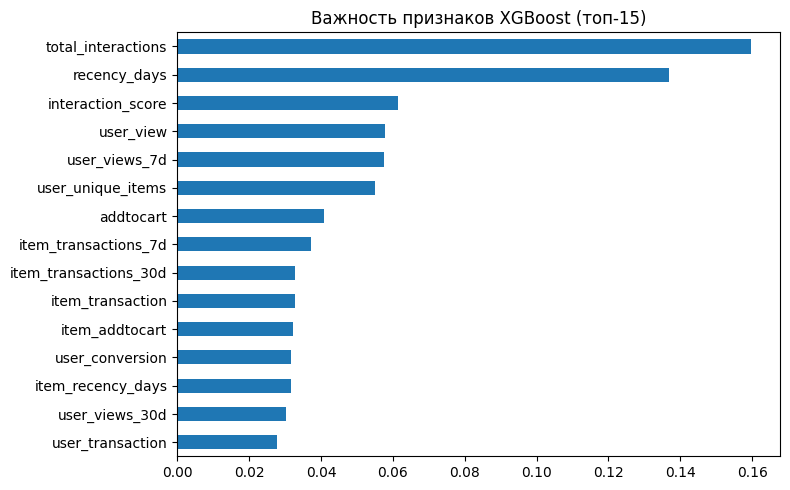

In [209]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt


def top_k_recs(df, scores, k=K):
    """{пользователь: [k товаров с наибольшим предсказанием]} (при равенстве - меньший itemid)."""
    ranked = (df[['visitorid', 'itemid']].assign(score=scores)
              .sort_values(['visitorid', 'score', 'itemid'], ascending=[True, False, True]))
    return ranked.groupby('visitorid').head(k).groupby('visitorid')['itemid'].agg(list).to_dict()


def fit_xgb(train_data, n_estimators=600, early_stopping=True, features=None, **extra_params):
    """Обучает XGBoost. early_stopping=False - обучить ровно n_estimators деревьев на всех строках (для финального test).
    features - список признаков (по умолчанию FEATURES)."""
    X, y = train_data[features or FEATURES], train_data['target']
    params = dict(n_estimators=n_estimators, learning_rate=0.05, max_depth=6, subsample=0.8,
                  colsample_bytree=0.8, eval_metric='aucpr', random_state=SEED, n_jobs=-1)
    params.update(extra_params)
    if early_stopping:
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
        tr, ho = next(splitter.split(X, y, groups=train_data['visitorid']))         # деление по ПОЛЬЗОВАТЕЛЯМ
        pos, neg = int((y.iloc[tr] == 1).sum()), int((y.iloc[tr] == 0).sum())
        params['scale_pos_weight'] = float(np.sqrt(neg / max(pos, 1)))
        model = XGBClassifier(early_stopping_rounds=30, **params)
        model.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[ho], y.iloc[ho])], verbose=False)
    else:
        pos, neg = int((y == 1).sum()), int((y == 0).sum())
        params['scale_pos_weight'] = float(np.sqrt(neg / max(pos, 1)))
        model = XGBClassifier(**params)
        model.fit(X, y, verbose=False)
    return model


xgb_model = fit_xgb(train_df)
xgb_best_n = int(xgb_model.best_iteration) + 1            # сколько деревьев оказалось лучшим - пригодится для финального test
print('Лучшее число деревьев:', xgb_best_n)

# ---- рекомендации и метрики на validation ----
xgb_scores = xgb_model.predict_proba(val_df[FEATURES])[:, 1]
recs_xgb = top_k_recs(val_df, xgb_scores)
val_per_user['XGBoost'] = per_user_metrics(recs_xgb, val_targets)

# ---- гибрид: известным - персональная история, новым - XGBoost ----
known_users = set(hist['visitorid'].unique())             # пользователи, у которых есть история до train_end
recs_hybrid = {u: (recommend_personal(u) if u in known_users else recs_xgb[u]) for u in val_users}
val_per_user['Гибрид: история + XGBoost'] = per_user_metrics(recs_hybrid, val_targets)

print(pd.DataFrame({name: df.mean() for name, df in val_per_user.items()}).T)

# ---- важность признаков ----
importance = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(importance.head(15))
importance.head(15).sort_values().plot.barh(figsize=(8, 5), title='Важность признаков XGBoost (топ-15)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'xgb_feature_importance.png', dpi=200, bbox_inches='tight')    # картинка для презентации
plt.show()

## **Факторизационная машина (FM)**

#### **Что такое FM**
Это линейная модель плюс **попарные взаимодействия признаков** через скрытые векторы. Для строки признаков `x`:

`z = w0 + Σ wⱼ·xⱼ + ½ · Σ_f [ (Σⱼ Vⱼf·xⱼ)² − Σⱼ (Vⱼf·xⱼ)² ]`,  вероятность покупки = `sigmoid(z)`

Первые два слагаемых — обычная логистическая регрессия; третье учитывает, как признаки работают **вместе** (например, "товар популярен" × "пользователь недавно был")

In [210]:
class Standardizer:
    """log1p + стандартизация; параметры запоминаются на обучающей выборке."""

    def fit(self, X):
        Z = np.log1p(np.clip(np.asarray(X, dtype=np.float64), 0, None))
        self.mean_, self.std_ = Z.mean(axis=0), Z.std(axis=0)
        self.std_[self.std_ == 0] = 1.0                      # константный столбец не делим на ноль
        return self

    def transform(self, X):
        Z = np.log1p(np.clip(np.asarray(X, dtype=np.float64), 0, None))
        return ((Z - self.mean_) / self.std_).astype(np.float32)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))


class FactorizationMachine:
    def __init__(self, n_factors=8, lr=0.02, reg=1e-4, epochs=6, batch_size=4096, pos_weight=1.0, seed=SEED):
        self.n_factors, self.lr, self.reg = n_factors, lr, reg
        self.epochs, self.batch_size, self.pos_weight, self.seed = epochs, batch_size, pos_weight, seed

    def _raw(self, X):
        XV = X @ self.V
        pair_term = 0.5 * (XV ** 2 - (X ** 2) @ (self.V ** 2)).sum(axis=1)
        return self.w0 + X @ self.w + pair_term, XV

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)
        n, d = X.shape
        rng = np.random.default_rng(self.seed)
        self.w0, self.w = 0.0, np.zeros(d, dtype=np.float32)
        self.V = (0.01 * rng.standard_normal((d, self.n_factors))).astype(np.float32)
        names = ['w0', 'w', 'V']
        m = {p: np.zeros_like(np.asarray(getattr(self, p), dtype=np.float32)) for p in names}    # Adam: среднее градиента
        v = {p: np.zeros_like(np.asarray(getattr(self, p), dtype=np.float32)) for p in names}    # Adam: среднее квадрата
        step = 0
        for _ in range(self.epochs):
            order = rng.permutation(n)
            for start in range(0, n, self.batch_size):
                idx = order[start:start + self.batch_size]
                xb, yb = X[idx], y[idx]
                z, XV = self._raw(xb)
                g = (sigmoid(z) - yb) * np.where(yb == 1, self.pos_weight, 1.0) / len(idx)
                grads = {'w0': np.float32(g.sum()),
                         'w': xb.T @ g + self.reg * self.w,
                         'V': xb.T @ (g[:, None] * XV) - ((xb ** 2).T @ g)[:, None] * self.V + self.reg * self.V}
                step += 1
                for p in names:
                    m[p] = 0.9 * m[p] + 0.1 * grads[p]
                    v[p] = 0.999 * v[p] + 0.001 * grads[p] ** 2
                    update = self.lr * (m[p] / (1 - 0.9 ** step)) / (np.sqrt(v[p] / (1 - 0.999 ** step)) + 1e-8)
                    setattr(self, p, getattr(self, p) - update)
        return self

    def predict_proba(self, X):
        return sigmoid(self._raw(np.asarray(X, dtype=np.float32))[0])


def fit_fm(train_data, **fm_params):
    scaler = Standardizer().fit(train_data[FEATURES])
    fm = FactorizationMachine(**fm_params).fit(scaler.transform(train_data[FEATURES]), train_data['target'])
    return scaler, fm


def fm_scores(model, df):
    scaler, fm = model
    return fm.predict_proba(scaler.transform(df[FEATURES]))


# ---- небольшая сетка параметров; выбираем по Precision@3 на validation ----
fm_rows, fm_best = [], None
for n_factors in (4, 8, 16):                    
    for pos_weight in (5, 20):
        model = fit_fm(train_df, n_factors=n_factors, pos_weight=pos_weight)
        recs = top_k_recs(val_df, fm_scores(model, val_df))
        p = per_user_metrics(recs, val_targets)['precision'].mean()
        fm_rows.append({'n_factors': n_factors, 'pos_weight': pos_weight, 'precision_at_3': p})
        if fm_best is None or p > fm_best['p']:
            fm_best = {'p': p, 'n_factors': n_factors, 'pos_weight': pos_weight, 'recs': recs}
display(pd.DataFrame(fm_rows).sort_values('precision_at_3', ascending=False))
val_per_user['FM'] = per_user_metrics(fm_best['recs'], val_targets)
print('Лучшая FM:', {k: v for k, v in fm_best.items() if k != 'recs'})

,n_factors,pos_weight,precision_at_3
3,8,20,0.022399
4,16,5,0.021810
1,4,20,0.020631
0,4,5,0.017978
5,16,20,0.016799
2,8,5,0.016210


Лучшая FM: {'p': np.float64(0.022399056881815503), 'n_factors': 8, 'pos_weight': 20}


## **Таблица validation с интервалами и выбор модели**

### **Как выбирать**
Берем модель с **лучшим Precision@3 на validation**. Если интервалы двух моделей сильно перекрываются, выбираем **более простую**

In [211]:
known_mask = np.asarray(val_users.isin(known_users))            # True - у покупателя есть история до train_end
base_precision = val_per_user['Популярность']['precision']

rows = []
for name, df in val_per_user.items():
    mean, low, high = bootstrap_ci(df['precision'])
    diff, diff_low, diff_high = paired_bootstrap_diff(df['precision'], base_precision)
    rows.append({'model': name, 'precision_at_3': mean, 'ci_low': low, 'ci_high': high,
                 'recall_at_3': df['recall'].mean(), 'hitrate_at_3': df['hit'].mean(),
                 'diff_vs_popularity': diff, 'diff_ci_low': diff_low, 'diff_ci_high': diff_high,
                 'precision_known': df['precision'][known_mask].mean(),
                 'precision_new': df['precision'][~known_mask].mean()})
validation_all = pd.DataFrame(rows).sort_values('precision_at_3', ascending=False).reset_index(drop=True)
validation_all.to_csv(RESULTS_DIR / 'validation_all_models.csv', index=False, encoding='utf-8-sig')
display(validation_all)

,model,precision_at_3,ci_low,ci_high,recall_at_3,hitrate_at_3,diff_vs_popularity,diff_ci_low,diff_ci_high,precision_known,precision_new
0,Персональная история 1/5/15,0.024167,0.018862,0.029767,0.055716,0.067197,0.017094,0.012378,0.022104,0.113990,0.005686
1,FM,0.022399,0.017094,0.027999,0.055315,0.061892,0.015326,0.010021,0.020925,0.115717,0.003198
2,Гибрид: история + XGBoost,0.022399,0.017094,0.027999,0.054449,0.061892,0.015326,0.010315,0.020631,0.113990,0.003554
3,XGBoost,0.021515,0.016505,0.026525,0.054947,0.062776,0.014441,0.009431,0.019452,0.108808,0.003554
4,Популярность,0.007073,0.004421,0.010028,0.011375,0.020336,0.000000,0.000000,0.000000,0.013817,0.005686


**Комментарий**
* Сложные модели не обогнали простую, и преимущества у них нет. Это не значит, что они хуже; это значит, что данные не позволяют различить

## **Финальный test. Часть 1**

In [212]:
# Вся доступная история до начала тестового периода (train + validation)
final_hist = events_df[events_df['date'] < val_end]
print('Последнее событие истории:', final_hist['date'].max())
print('Начало тестового периода:', val_end)

# Фиксированные веса выбранной на validation модели
final_event_weights = dict(EVENT_WEIGHTS)
final_user_item_scores = pair_scores(final_hist, final_event_weights)      # суммарный интерес каждого пользователя к товару

# Пользователи, встречавшиеся до начала теста, и популярные товары по всей истории до теста
final_user_ids = final_hist['visitorid'].unique()
final_purchases = final_hist[final_hist['event'] == 'transaction']
final_popular_top3 = final_purchases['itemid'].value_counts().head(3).index.tolist()
print(final_popular_top3)

recommend_final_personal = make_personal_recommender(final_user_item_scores, final_user_ids, final_popular_top3)
print(recommend_final_personal(example_user_id))

# Покупки в тестовом периоде
test_purchases = test_events[test_events['event'] == 'transaction'].copy()
test_targets = test_purchases.groupby('visitorid')['itemid'].agg(set)
print('Событий покупки в test:', len(test_purchases))
print('Покупателей в test:', len(test_targets))

Последнее событие истории: 2015-09-04 02:59:46.763000
Начало тестового периода: 2015-09-04 02:59:47.788000
[461686, 119736, 213834]
[144587, 227880, 399829]
Событий покупки в test: 1897
Покупателей в test: 1057


Покупателей: 1057
Test Precision@3, персональная модель: 0.029013
Test Precision@3, популярность: 0.015768
Прирост относительно популярности: 84.00%
Попаданий: 92 против 50 из 3171 рекомендаций; абсолютная разница Precision@3: +0.013245
Персональная: 0.029013 [0.023021; 0.035005] | популярность: 0.015768 [0.011668; 0.020183]
Разность: +0.013245 (95% Доверительный итервал [+0.008515; +0.018291]) - если интервал не содержит 0, прирост надёжен


,count,mean
known_user,,
False,858,0.013986
True,199,0.093802


,model,precision_at_3,ci_low,ci_high,buyers_count
0,Популярность,0.015768,0.011668,0.020183,1057
1,Персональная модель 1/5/15,0.029013,0.023021,0.035005,1057


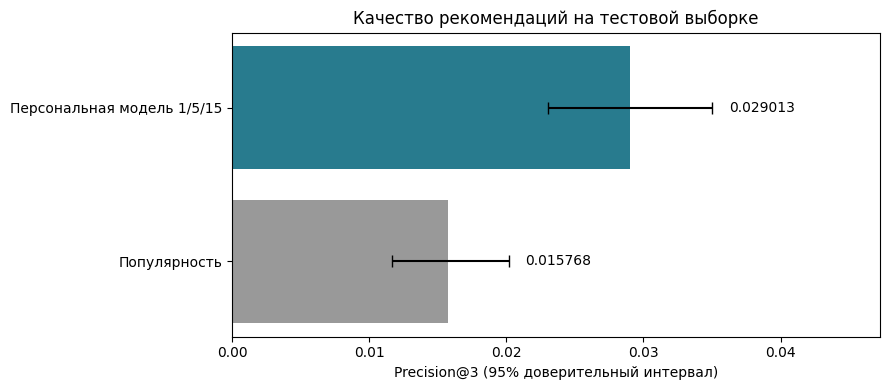

In [213]:
test_personal_precisions = precision_list(recommend_final_personal, test_targets)
test_personal_precision_at_3 = sum(test_personal_precisions) / len(test_personal_precisions)
print('Покупателей:', len(test_personal_precisions))
print(f'Test Precision@3, персональная модель: {test_personal_precision_at_3:.6f}')

# Одинаковые рекомендации базовой модели для всех покупателей
test_popularity_precisions = precision_of_fixed_items(final_popular_top3, test_targets)
test_popularity_precision_at_3 = sum(test_popularity_precisions) / len(test_popularity_precisions)
print(f'Test Precision@3, популярность: {test_popularity_precision_at_3:.6f}')

# Относительный прирост качества к базовой модели, в процентах
test_improvement_pct = (test_personal_precision_at_3 / test_popularity_precision_at_3 - 1) * 100
print(f'Прирост относительно популярности: {test_improvement_pct:.2f}%')

# Абсолютные величины и интервалы: «+84%» без базы звучит ярче, чем есть на самом деле
slots = K * len(test_targets)
hits_personal = round(sum(test_personal_precisions) * K)
hits_popularity = round(sum(test_popularity_precisions) * K)
print(f'Попаданий: {hits_personal} против {hits_popularity} из {slots} рекомендаций; '
      f'абсолютная разница Precision@3: {test_personal_precision_at_3 - test_popularity_precision_at_3:+.6f}')
mean_p, low_p, high_p = bootstrap_ci(test_personal_precisions)
mean_b, low_b, high_b = bootstrap_ci(test_popularity_precisions)
diff, diff_low, diff_high = paired_bootstrap_diff(test_personal_precisions, test_popularity_precisions)
print(f'Персональная: {mean_p:.6f} [{low_p:.6f}; {high_p:.6f}] | популярность: {mean_b:.6f} [{low_b:.6f}; {high_b:.6f}]')
print(f'Разность: {diff:+.6f} (95% Доверительный итервал [{diff_low:+.6f}; {diff_high:+.6f}]) - если интервал не содержит 0, прирост надёжен')

# Результаты по сегментам: известные / новые покупатели
test_known_users_mask = test_targets.index.isin(final_user_ids)
personal_test_results = pd.DataFrame({
    'visitorid': test_targets.index,
    'known_user': test_known_users_mask,
    'precision_at_3': test_personal_precisions
})
test_segment_results = personal_test_results.groupby('known_user')['precision_at_3'].agg(['count', 'mean'])
display(test_segment_results)
personal_test_results.to_csv(RESULTS_DIR / 'personal_test_results.csv', index=False)

# Обе модели оценены на одних и тех же тестовых покупателях
test_results = pd.DataFrame({
    'model': ['Популярность', 'Персональная модель 1/5/15'],
    'precision_at_3': [test_popularity_precision_at_3, test_personal_precision_at_3],
    'ci_low': [low_b, low_p],
    'ci_high': [high_b, high_p],
    'buyers_count': [len(test_targets), len(test_targets)]
})
display(test_results)
test_results.to_csv(RESULTS_DIR / 'test_model_comparison.csv', index=False, encoding='utf-8-sig')

# График (один; "усы" - 95% доверительный интервал)
errors = [(test_results['precision_at_3'] - test_results['ci_low']).values,
          (test_results['ci_high'] - test_results['precision_at_3']).values]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(test_results['model'], test_results['precision_at_3'], xerr=errors, capsize=4, color=['#999999', '#287B8E'])
ax.bar_label(bars, fmt='%.6f', padding=12)              # подписи значений рядом с полосами
ax.set_xlabel('Precision@3 (95% доверительный интервал)')
ax.set_ylabel('')
ax.set_title('Качество рекомендаций на тестовой выборке')
ax.set_xlim(0, test_results['ci_high'].max() * 1.35)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'test_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

**Комментарий** 
* Персональная модель дала примерно на 84% выше Precision@3 — это 92 попадания против 50 среди 3171 рекомендации
* На тестовой выборке персональная модель с весами 1/5/15 получила Precision@3 = 0,029013 против 0,015768 у популярности - относительный прирост 84%. Для 199 покупателей с историей метрика составила 0,093802, для 858 новых - 0,013986. Новые покупатели получают популярные товары. Настройки модели выбраны по validation

## **Финальный test. Часть 2**

In [214]:
BEST_MODEL = 'personal'   

if BEST_MODEL is None:
    print('Сначала выберите модель по таблице validation и заполните BEST_MODEL.')
else:
    test_users = test_targets.index
    recs_test_popular = {u: list(final_popular_top3) for u in test_users}
    recs_test_personal = {u: recommend_final_personal(u) for u in test_users}

    if BEST_MODEL == 'personal':
        recs_test = recs_test_personal
    else:
        # --- обучение: признаки до train_end, метки = покупки validation ---
        fit_pair, fit_user, fit_item = build_tables(hist, train_end)
        fit_users = sample_training_users(hist, val_targets.index)
        fit_popular = hist[hist['event'] == 'transaction']['itemid'].value_counts().head(POPULAR_N).index.tolist()
        test_train_df = build_dataset(fit_users, fit_pair, fit_user, fit_item, fit_popular, val_targets)

        # --- оценка: признаки до val_end, метки = покупки test ---
        test_pair, test_user, test_item = build_tables(final_hist, val_end)
        test_popular = final_hist[final_hist['event'] == 'transaction']['itemid'].value_counts().head(POPULAR_N).index.tolist()
        test_df = build_dataset(test_users, test_pair, test_user, test_item, test_popular, test_targets)

        if BEST_MODEL in ('xgb', 'hybrid'):
            model = fit_xgb(test_train_df, n_estimators=xgb_best_n, early_stopping=False)
            recs_model = top_k_recs(test_df, model.predict_proba(test_df[FEATURES])[:, 1])
        elif BEST_MODEL == 'fm':
            model = fit_fm(test_train_df, n_factors=fm_best['n_factors'], pos_weight=fm_best['pos_weight'])
            recs_model = top_k_recs(test_df, fm_scores(model, test_df))
        else:
            raise ValueError("BEST_MODEL должен быть 'personal', 'xgb', 'hybrid' или 'fm'")

        if BEST_MODEL == 'hybrid':
            known_test = set(final_hist['visitorid'].unique())
            recs_test = {u: (recs_test_personal[u] if u in known_test else recs_model[u]) for u in test_users}
        else:
            recs_test = recs_model

    chosen = per_user_metrics(recs_test, test_targets)
    baseline = per_user_metrics(recs_test_popular, test_targets)
    mean, low, high = bootstrap_ci(chosen['precision'])
    b_mean, b_low, b_high = bootstrap_ci(baseline['precision'])
    diff, d_low, d_high = paired_bootstrap_diff(chosen['precision'], baseline['precision'])

    test_known = np.asarray(test_users.isin(set(final_hist['visitorid'].unique())))
    test_final = pd.DataFrame([
        {'model': 'Популярность', 'precision_at_3': b_mean, 'ci_low': b_low, 'ci_high': b_high},
        {'model': BEST_MODEL, 'precision_at_3': mean, 'ci_low': low, 'ci_high': high}])
    test_final.to_csv(RESULTS_DIR / 'test_final.csv', index=False, encoding='utf-8-sig')
    display(test_final)
    print(f'Покупателей в test: {len(test_users)} (известных: {int(test_known.sum())})')
    print(f'Прирост: {diff:+.6f} (95% Доверительный интервал [{d_low:+.6f}; {d_high:+.6f}]); относительно {mean / b_mean - 1:+.0%}')
    print(f"Известные: {chosen['precision'][test_known].mean():.6f} | новые: {chosen['precision'][~test_known].mean():.6f}")

,model,precision_at_3,ci_low,ci_high
0,Популярность,0.015768,0.011668,0.020183
1,personal,0.029013,0.023021,0.035005


Покупателей в test: 1057 (известных: 199)
Прирост: +0.013245 (95% Доверительный интервал [+0.008515; +0.018291]); относительно +84%
Известные: 0.093802 | новые: 0.013986


## **Артефакты, API и веб-сервис**
- `user_top.json` — словарь "пользователь → его топ-3 товара по сумме весов 1/5/15";
- `popular.json` — список популярных товаров для дополнения и для новых пользователей
- `metrics.json` — отдаёт endpoint `/metrics`

> Для **сервиса** модель обучается на **всех** данных (до конца датасета), а отчётные метрики взяты из test

In [215]:
import json
from pathlib import Path

ARTIFACTS_DIR = Path('artifacts')            
for folder in ('artifacts', 'service', 'tests'):
    Path(folder).mkdir(exist_ok=True)
Path('service/__init__.py').touch()          


def top_items_per_user(events, weights, k=K):
    """{пользователь: [k лучших товаров по сумме весов]}; порядок при равенстве детерминирован."""
    w = events['event'].map(weights)
    scores = w.groupby([events['visitorid'], events['itemid']]).sum().rename('score').reset_index()
    scores = scores.sort_values(['visitorid', 'score', 'itemid'], ascending=[True, False, True])
    scores['rank'] = scores.groupby('visitorid').cumcount()
    top = scores[scores['rank'] < k]
    return {int(u): [int(i) for i in items] for u, items in top.groupby('visitorid')['itemid'].agg(list).items()}


service_user_top = top_items_per_user(events_df, event_weights)                    # на ВСЕХ данных
service_popular = [int(i) for i in events_df[events_df['event'] == 'transaction']['itemid'].value_counts().head(20).index]

(ARTIFACTS_DIR / 'user_top.json').write_text(json.dumps(service_user_top), encoding='utf-8')
(ARTIFACTS_DIR / 'popular.json').write_text(json.dumps(service_popular), encoding='utf-8')

metrics = {
    'model': 'personal_history_plus_popular',
    'event_weights': event_weights,
    'k': K,
    'metric': 'Precision@3 по покупкам в следующие 14 дней; усреднение по покупателям периода',
    'test_period_start': str(val_end),
    'test_period_end': str(max_date),
    'buyers_in_test': int(len(test_targets)),
    'precision_at_3_test_personal': float(globals().get('test_personal_precision_at_3', float('nan'))),
    'precision_at_3_test_popularity': float(globals().get('test_popularity_precision_at_3', float('nan'))),
    'note': 'Метрики оффлайн; влияние на оборот не измерялось. Сервисная модель обучена на всех данных до конца датасета.',
}
if 'test_final' in globals():                                                       # интервалы из шага 10, если он выполнялся
    metrics['test_final_with_ci'] = test_final.to_dict(orient='records')
(ARTIFACTS_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Пользователей в словаре:', len(service_user_top), '| популярных:', len(service_popular))

Пользователей в словаре: 1407580 | популярных: 20


## **Файл сервиса `service/app.py`**
Ячейка ниже создаёт файл командой `%%writefile` (она должна быть первой строкой ячейки).

### **Что делает код**
- `FastAPI()` создаёт веб-приложение; декоратор `@app.get('/путь')` связывает адрес с функцией: на GET-запрос по этому адресу вызывается функция.
- `lifespan` - код, который выполняется один раз при старте: три файла (`user_top.json`, `popular.json`, `metrics.json`) читаются в память, а не при каждом запросе. Если файла нет, сервис всё равно стартует, но `/health`, `/metrics` и `/recommend` отвечают кодом 503.
- `recommend_items` - логика рекомендаций: товары из истории пользователя, затем дополнение популярными без повторов, всего три.
- `user_id: int = PathParam(..., ge=0)` - FastAPI сам проверяет, что значение целое и неотрицательное; для `abc`, `-5`, `1.5` возвращается код 422 с описанием ошибки (а не 500). Так реализована обработка некорректных запросов.
- Неизвестный пользователь не вызывает ошибку: в словаре для него нет записи, поэтому он получает популярные товары (`source: popular`). Это сценарий холодного старта.

In [216]:
%%writefile service/app.py
"""HTTP-сервис рекомендаций (FastAPI).

Запуск:  uvicorn service.app:app --reload --port 8000     Документация: http://localhost:8000/docs
"""
import json
import os
from contextlib import asynccontextmanager
from pathlib import Path

from fastapi import FastAPI, HTTPException
from fastapi import Path as PathParam

ARTIFACTS_DIR = Path(os.environ.get('ARTIFACTS_DIR', 'artifacts'))
K = 3
state = {}


def recommend_items(user_top, popular, user_id, k=K):
    """Свои товары пользователя, затем популярные без повторов; всего k."""
    items = list(user_top.get(user_id, []))
    for item_id in popular:
        if len(items) >= k:
            break
        if item_id not in items:
            items.append(item_id)
    return items


@asynccontextmanager
async def lifespan(app):
    try:
        raw = json.loads((ARTIFACTS_DIR / 'user_top.json').read_text(encoding='utf-8'))
        state['user_top'] = {int(u): items for u, items in raw.items()}          # ключи JSON - строки, возвращаем числа
        state['popular'] = json.loads((ARTIFACTS_DIR / 'popular.json').read_text(encoding='utf-8'))
        state['metrics'] = json.loads((ARTIFACTS_DIR / 'metrics.json').read_text(encoding='utf-8'))
    except FileNotFoundError as error:
        state['error'] = f'не найден файл артефактов: {error.filename}'
    yield
    state.clear()


app = FastAPI(title='Recommender service', version='1.0.0', lifespan=lifespan)


def require_model():
    if 'user_top' not in state:
        raise HTTPException(status_code=503, detail=state.get('error', 'модель не загружена'))


@app.get('/health')
def health():
    require_model()
    return {'status': 'ok', 'users_in_model': len(state['user_top']), 'popular_items': len(state['popular'])}


@app.get('/metrics')
def metrics():
    require_model()
    return state['metrics']


@app.get('/recommend/{user_id}')
def recommend(user_id: int = PathParam(..., ge=0, description='visitorid - неотрицательное целое')):
    require_model()
    items = recommend_items(state['user_top'], state['popular'], user_id)
    return {'user_id': user_id, 'items': items,
            'source': 'personal' if user_id in state['user_top'] else 'popular'}

Overwriting service/app.py


In [217]:
%%writefile tests/test_service.py
import importlib
import json

import pytest

pytest.importorskip('fastapi')
pytest.importorskip('httpx')
from fastapi.testclient import TestClient


@pytest.fixture()
def client(tmp_path, monkeypatch):
    (tmp_path / 'user_top.json').write_text(json.dumps({'7': [11, 12, 13], '8': [11]}))
    (tmp_path / 'popular.json').write_text(json.dumps([100, 101, 102, 103]))
    (tmp_path / 'metrics.json').write_text(json.dumps({'precision_at_3_test_personal': 0.03}))
    monkeypatch.setenv('ARTIFACTS_DIR', str(tmp_path))
    import service.app as app_module
    importlib.reload(app_module)                       # заново читаем ARTIFACTS_DIR
    with TestClient(app_module.app) as test_client:
        yield test_client


def test_health(client):
    assert client.get('/health').json()['status'] == 'ok'


def test_known_user(client):
    assert client.get('/recommend/7').json() == {'user_id': 7, 'items': [11, 12, 13], 'source': 'personal'}


def test_short_history_is_padded_with_popular(client):
    assert client.get('/recommend/8').json()['items'] == [11, 100, 101]


def test_unknown_user_gets_popular(client):
    body = client.get('/recommend/999999').json()
    assert body['items'] == [100, 101, 102] and body['source'] == 'popular'


@pytest.mark.parametrize('bad', ['abc', '-5', '1.5'])
def test_invalid_user_id_is_422(client, bad):
    assert client.get(f'/recommend/{bad}').status_code == 422


def test_metrics(client):
    assert client.get('/metrics').json()['precision_at_3_test_personal'] == 0.03

Overwriting tests/test_service.py


## **Docker**

### Файлы Docker-образа (ячейки ниже создают их командой `%%writefile`)
- `requirements-service.txt` - зависимости сервиса (FastAPI и uvicorn). Библиотеки ноутбука (`pandas`, `xgboost`, `implicit`) в образ не входят: так образ получается меньше и собирается быстрее.
- `Dockerfile` - инструкция сборки образа:
  - `FROM python:3.11-slim` - базовый образ с Python;
  - `ENV ...` - переменные окружения; `ARTIFACTS_DIR=/app/artifacts` - папка, где сервис ищет json-файлы;
  - `WORKDIR /app` - рабочая папка внутри контейнера;
  - `COPY requirements-service.txt .` и `RUN pip install ...` выполняются **до** копирования кода: Docker кэширует этот слой, и при правке кода пакеты не ставятся заново;
  - `COPY service ./service` и `COPY artifacts ./artifacts` - код сервиса и артефакты модели;
  - `USER appuser` - сервис запускается не от root (безопасность);
  - `HEALTHCHECK` - раз в 30 секунд Docker обращается к `/health`; при ответе 503 контейнер считается нездоровым;
  - `CMD [...]` - команда запуска; `--host 0.0.0.0` нужен, чтобы сервис был доступен снаружи контейнера.
- `.dockerignore` - что не копировать в образ (данные, ноутбуки, тесты).

Версии в `requirements-service.txt` указаны диапазонами; точные версии установленных пакетов можно получить командой `python -m pip freeze`

In [218]:
%%writefile requirements-service.txt
fastapi>=0.110,<1.0
uvicorn[standard]>=0.29,<1.0

Overwriting requirements-service.txt


In [219]:
%%writefile Dockerfile
FROM python:3.11-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    ARTIFACTS_DIR=/app/artifacts

WORKDIR /app

COPY requirements-service.txt .
RUN pip install --no-cache-dir -r requirements-service.txt

COPY service ./service
COPY artifacts ./artifacts

RUN useradd --create-home appuser && chown -R appuser /app
USER appuser

EXPOSE 8000

HEALTHCHECK --interval=30s --timeout=3s --start-period=10s \
  CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"

CMD ["uvicorn", "service.app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting Dockerfile


In [220]:
%%writefile .dockerignore
*.ipynb
.ipynb_checkpoints/
data/
results/
tests/
__pycache__/
*.pyc
*.tar
.git

Overwriting .dockerignore


## **Итоговый график результатов для слайда**

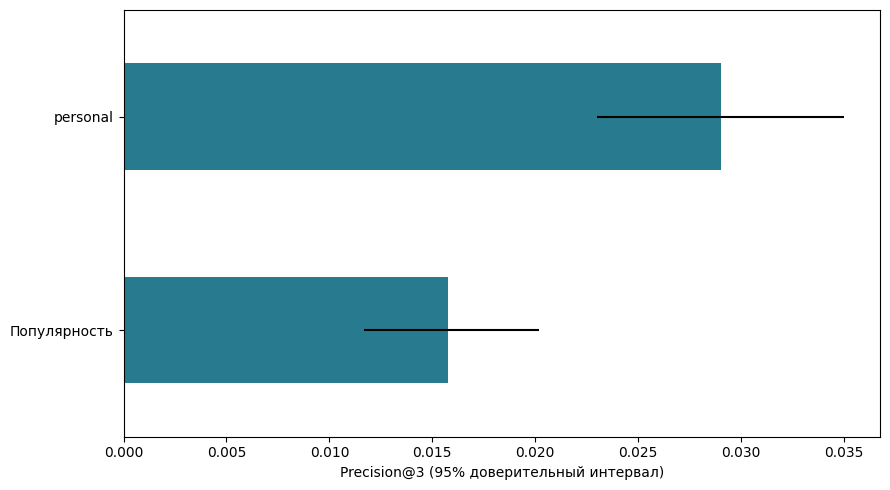

In [221]:
table = test_final if 'test_final' in globals() else validation_all          
table = table.sort_values('precision_at_3')
errors = [table['precision_at_3'] - table['ci_low'], table['ci_high'] - table['precision_at_3']]
ax = table.plot.barh(x='model', y='precision_at_3', xerr=errors, legend=False, figsize=(9, 5), color='#287B8E')
ax.set_xlabel('Precision@3 (95% доверительный интервал)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'results_with_ci.png', dpi=200, bbox_inches='tight')
plt.show()

## **Проверка воспроизводимости**

In [222]:
import json
import platform
import sys
from importlib import metadata

packages = ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'xgboost', 'implicit', 'fastapi', 'uvicorn', 'pytest', 'httpx']
lines = []
for name in packages:
    try:
        lines.append(f'{name}=={metadata.version(name)}')
    except metadata.PackageNotFoundError:
        print('не установлен:', name)
Path('requirements-lock.txt').write_text('\n'.join(lines) + '\n', encoding='utf-8')

run_info = {'python': sys.version.split()[0], 'platform': platform.platform(), 'seed': SEED,
            'train_end': str(train_end), 'val_end': str(val_end), 'max_date': str(max_date)}
Path('run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding='utf-8')

expected_files = [RESULTS_DIR / 'validation_all_models.csv', RESULTS_DIR / 'eda_user_activity.png',
                  RESULTS_DIR / 'eda_item_purchases.png', ARTIFACTS_DIR / 'user_top.json',
                  ARTIFACTS_DIR / 'popular.json', ARTIFACTS_DIR / 'metrics.json']
missing = [str(p) for p in expected_files if not p.exists()]
assert not missing, f'не найдены файлы: {missing}'
print('Все ожидаемые файлы на месте. Версии записаны в requirements-lock.txt, параметры прогона - в run_info.json')

Все ожидаемые файлы на месте. Версии записаны в requirements-lock.txt, параметры прогона - в run_info.json


In [223]:
print(f'Полный прогон: {(time.time() - RUN_START) / 60:.1f} мин')

Полный прогон: 33.3 мин
